# The Cignetti and The Noise: A Model for Predicitng Power 4 College

Football Coaching Hire Success

Anonymous Author  
November 10, 2026

Using data on 117 recent Power 4 college football hires, we built a statistical model for predicting a coach’s success at their new school. For each hire, we collected data about their background and experiences, the previous success as a head coach or coordinator and their success since hiring. Over 50 variables on these factors were recorded though we used 29 of these in building our predictive model. Our measure of success is based upon Bill Connelly’s SP+ team ratings relative to the performance on the same metric of the school in the 15 years prior to their selection as head coach. Using a cross-validated regularized linear regression, we obtain a predictive model for coaching success. Among the important factors for predicting a successful hire are having been a previous college head coach, leaving a job as an Offensive Coordinator, age and quality of the hiring school’s team in the previous 15 years. While we do find these factors are important for the prediction of a successful coaching hire, the trends here are weak. With 66% accuracy, the model does identify coaching hires that will outperform team performance in the 15 years before the hire. However, no combination of these factors leads to high predictability of identifying a successful coaching hire.

In [ ]:
knitr::opts_chunk$set(echo = FALSE)

In [ ]:
library(stringr)
library(english)
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ purrr     1.2.2
✔ forcats   1.0.1     ✔ readr     2.2.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

# Introduction

College football is big business. The changes due to the use of player’s name, image and license (NIL) that allow players to be openly (and appropriately) paid for their services, has brought a new influx of funds. A December 2024 study by CNBC using fiscal year 2023 numbers estimated that the top university athletic programs are valued at over \$1 billion US dollars and have annual revenue of over \$200 million \[@cnbc_college_worth\]. Unsurprisingly the executive that leads the college football operation, the head coach, are well compensated. In a 2023 study, David Evans found that “80% of the Highest-Earning Public Employees are College Head Coaches” \[@highest_state\].

Being a successful college football head coach requires multifaceted talent in a variety of areas including player development, staff management, in gameday decision making, in player evaluation and in recruitment of players. Consequently, the selection of a new coach for top universities is an important one. This paper proposes two novel contributions. First, we propose methodology for evaluating coaching hires by comparing coaching success to previous performance at a given institution.  
Using those performance measures we build a model to predict which coaching hires will be successful using hand collected data about each coach’s background, experiences, and previous success as a coach. Second, we develop a machine learning predictive model which finds that there are a few factors that discernibly predict a coaching hire’s future performance. However, it is clear that our model’s predictions are far from certain and that there is a great deal of noise relative to the signals in the data about who would make a successful coach.

In the rest of this paper we describe our measure for coaching success and then we look at past hiring of college football head coaches to build a predictive model of the characteristics and factors that influence their success. The next Section introduces the data that we collected through both automated and manual means. Summaries of the variables we used as predictors are given in Section 3. We describe our model building process and results in Section 4. Finally we conclude with a discussion of our results.

# Data

The data set used for this analysis is a collection of Power 4 plus the University of Notre Dame (IN) coaching hires. We will refer to this group as P4 schools. The P4 conferences are the Atlantic Coast Conference (ACC), Big 12, Big Ten and Southeastern Conference (SEC). We began with all coaching hires who started coaching during the 2016 season or since. We added at least once coach from each school so that Kirk Ferentz is in our data. That gave us hires.

Specifically, we include P4 coaching hires who started coaching between 2016 and 2024. As our observational units, we chose hires rather than coaches, since it is the outcome of the hiring process we are trying to maximize. Consequently, Kirk Ferentz, the current dean of college football, is in the data. Nick Saban is not among our data, but James Franklin is in the data, as the only Penn State coach over this time period. Matt Rhule appears twice having been hired at Baylor (in 2017) and at Nebraska (in 2023). We did not include interim coaches and, of course, as the title implies Curt Cignetti is one of our observations and an outlier. In total there are 117 coaching hires in these data.

For each hire in our data, we recorded over $50$ measurements about their past history though we used 30 as predictors below. Generally these fall into three categories: background variables, previous coaching performance, and performance metrics in the job for which they were hired. Included in the background variables are information about their coaching career, their previous coaching positions, whether or not they have previously coached in the NFL, whether or not they had previously been a HC, whether they had played or coached previously at the hiring institution, etc. Previous coaching performance variables are recorded and include previous performance as a college head coach. Variables on a coaches background included features such as whether or not they had a previous connection to the hiring school, whether they played P4 football, and whether they had coached in the NFL. A full list of all variables is presented in @tbl-var of the Appendix. One of the metrics we considered was having a connection to the hiring school by being an alumni or having played there or having coached there. Having an alumni as your head coach was previously analyzed by Josh Planos of FiveThirtyEight and found to not impact coaching success either way \[@alumni_538\]. ZZZ need to add the more recent articles ZZZ. To account for regression to the mean, a team that was underperforming relative to historical averages before a coach arrived, we also included the team’s average performance for the five years before the hired coach arrived.

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>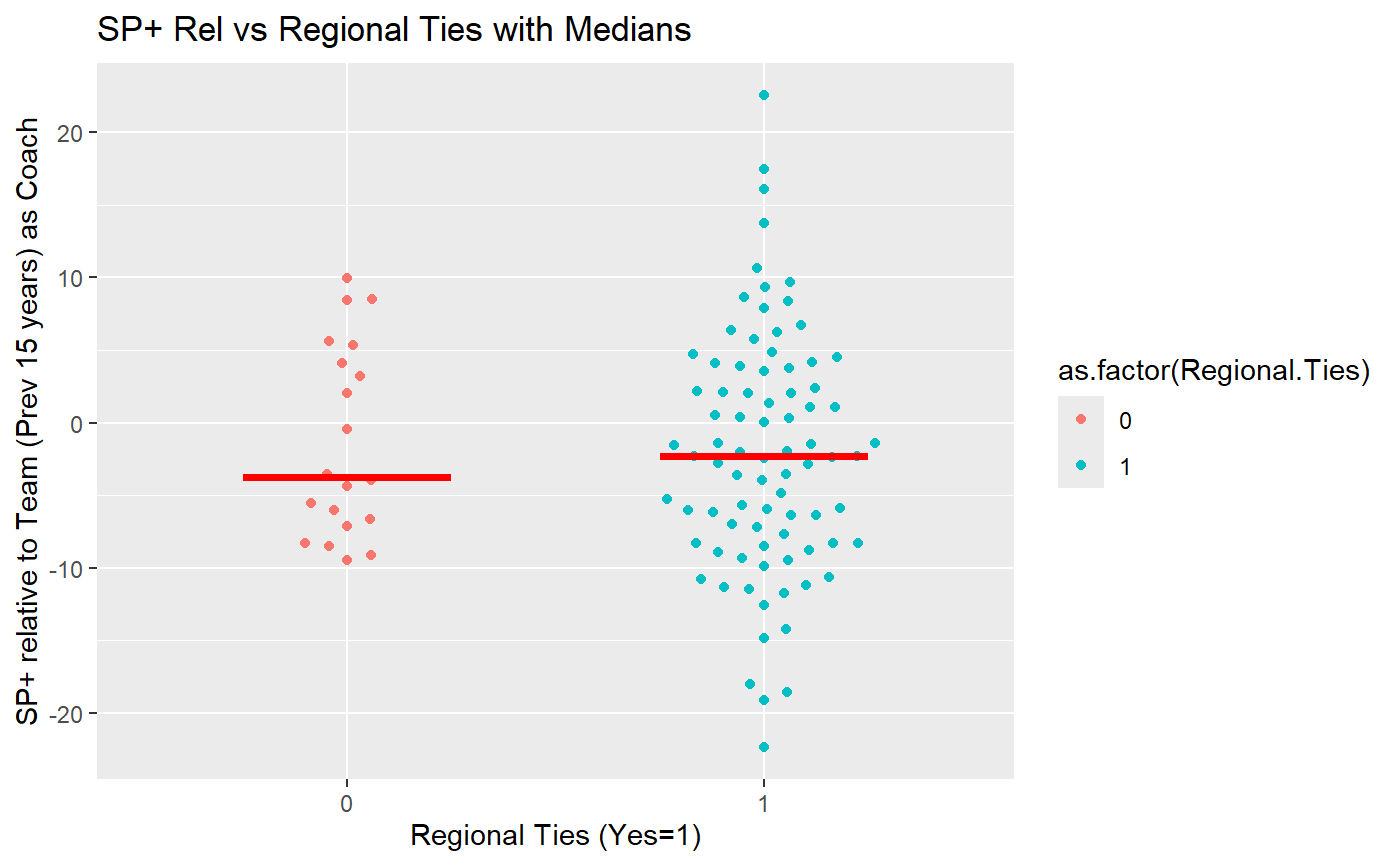</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>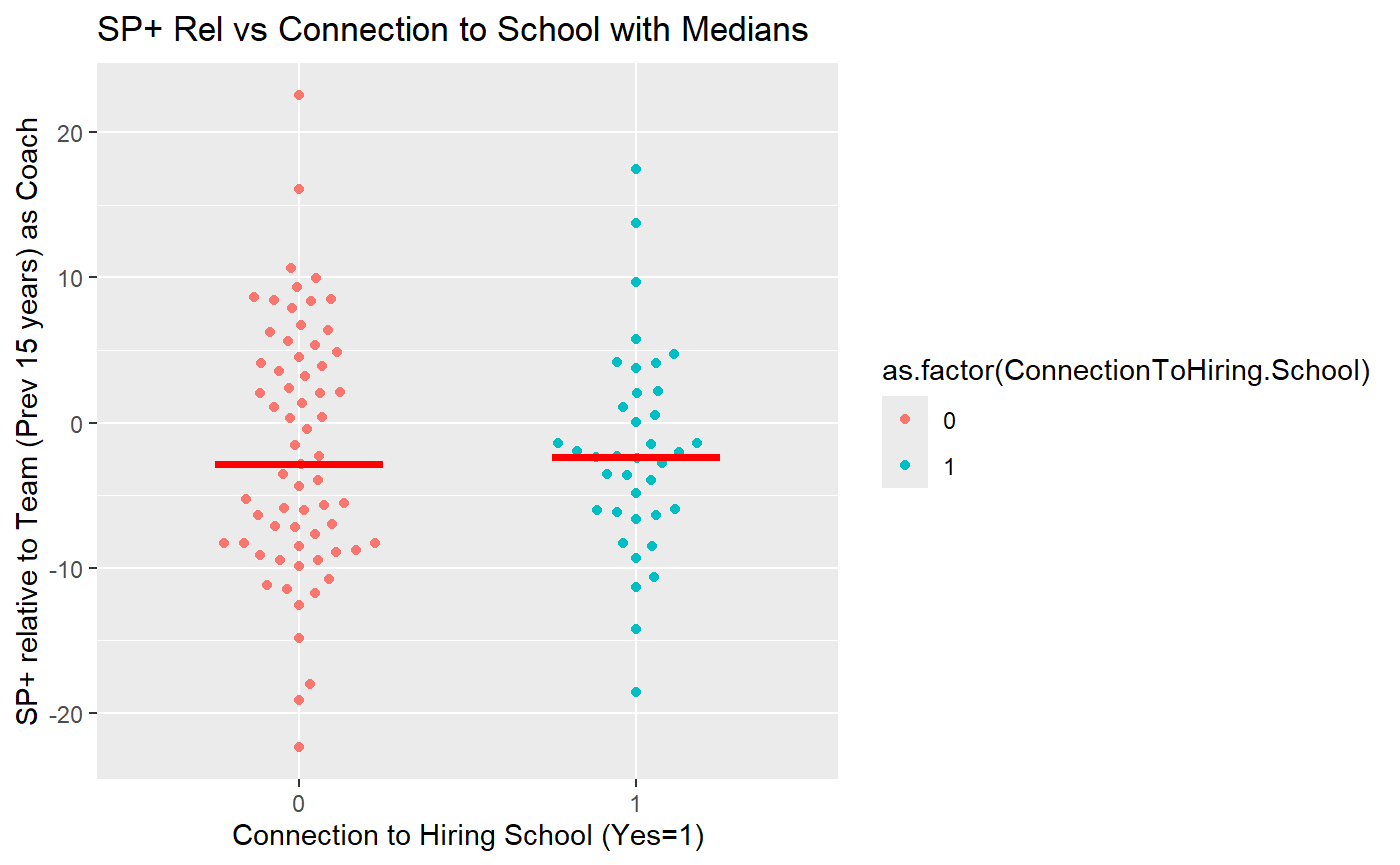</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>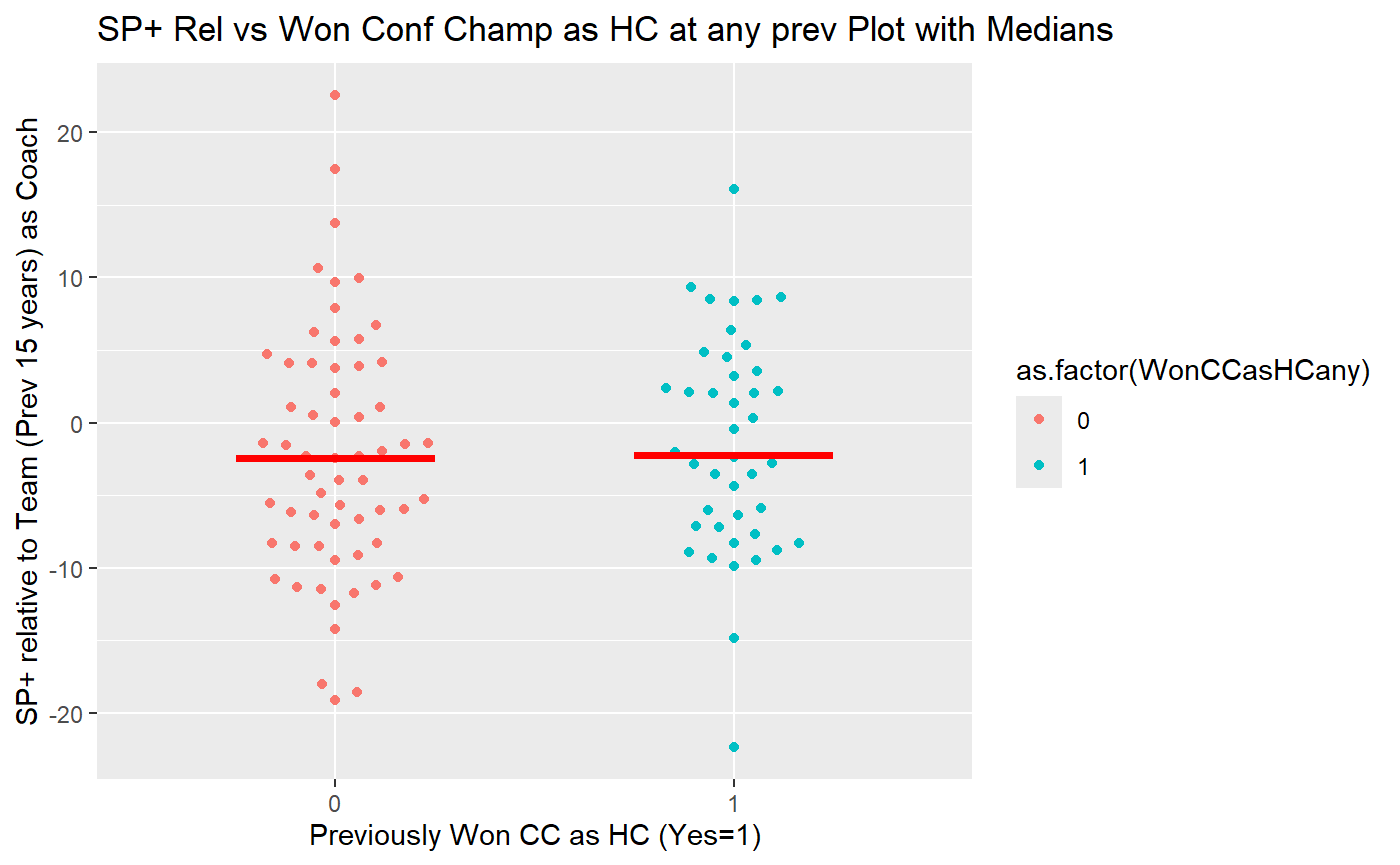</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>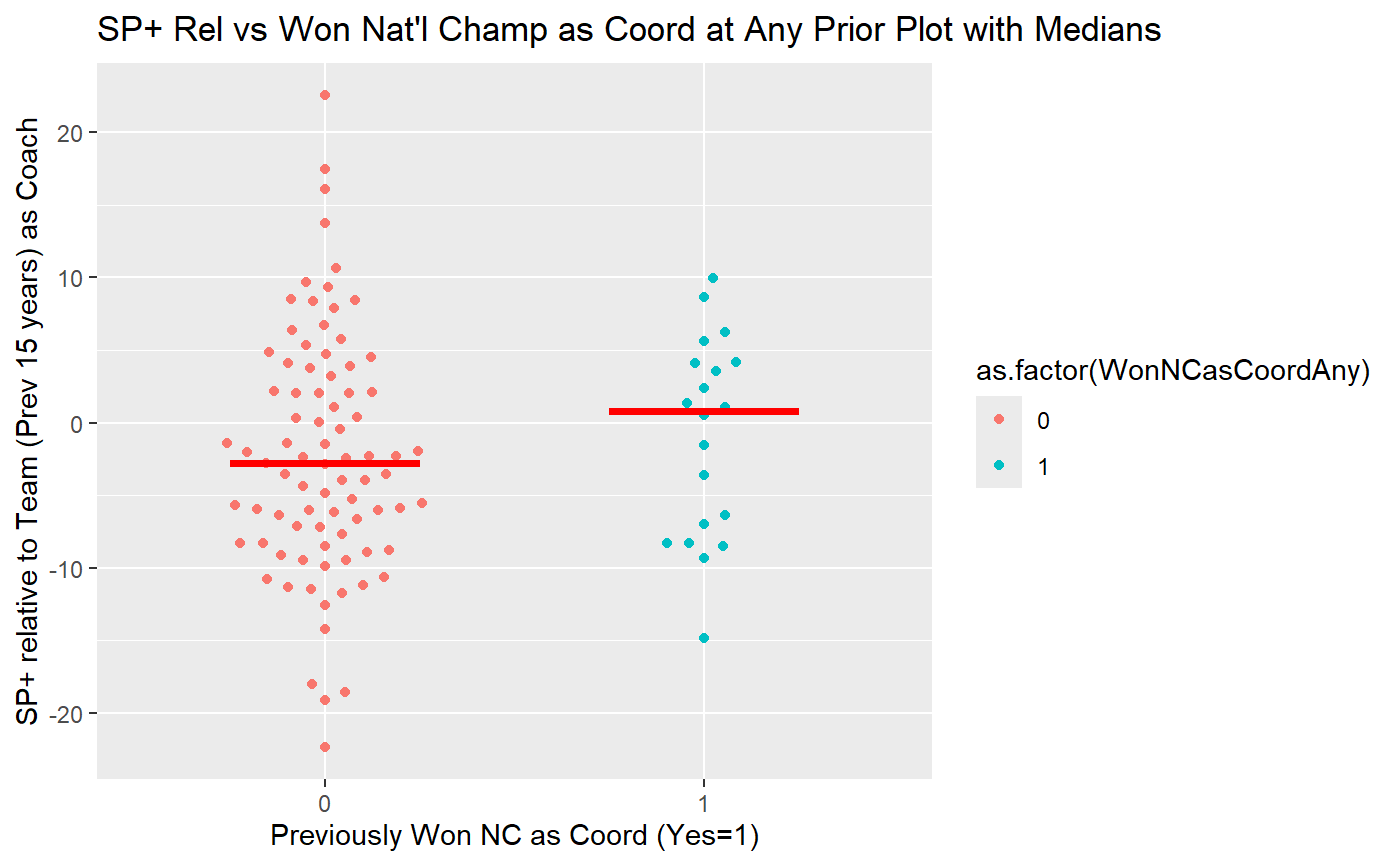</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>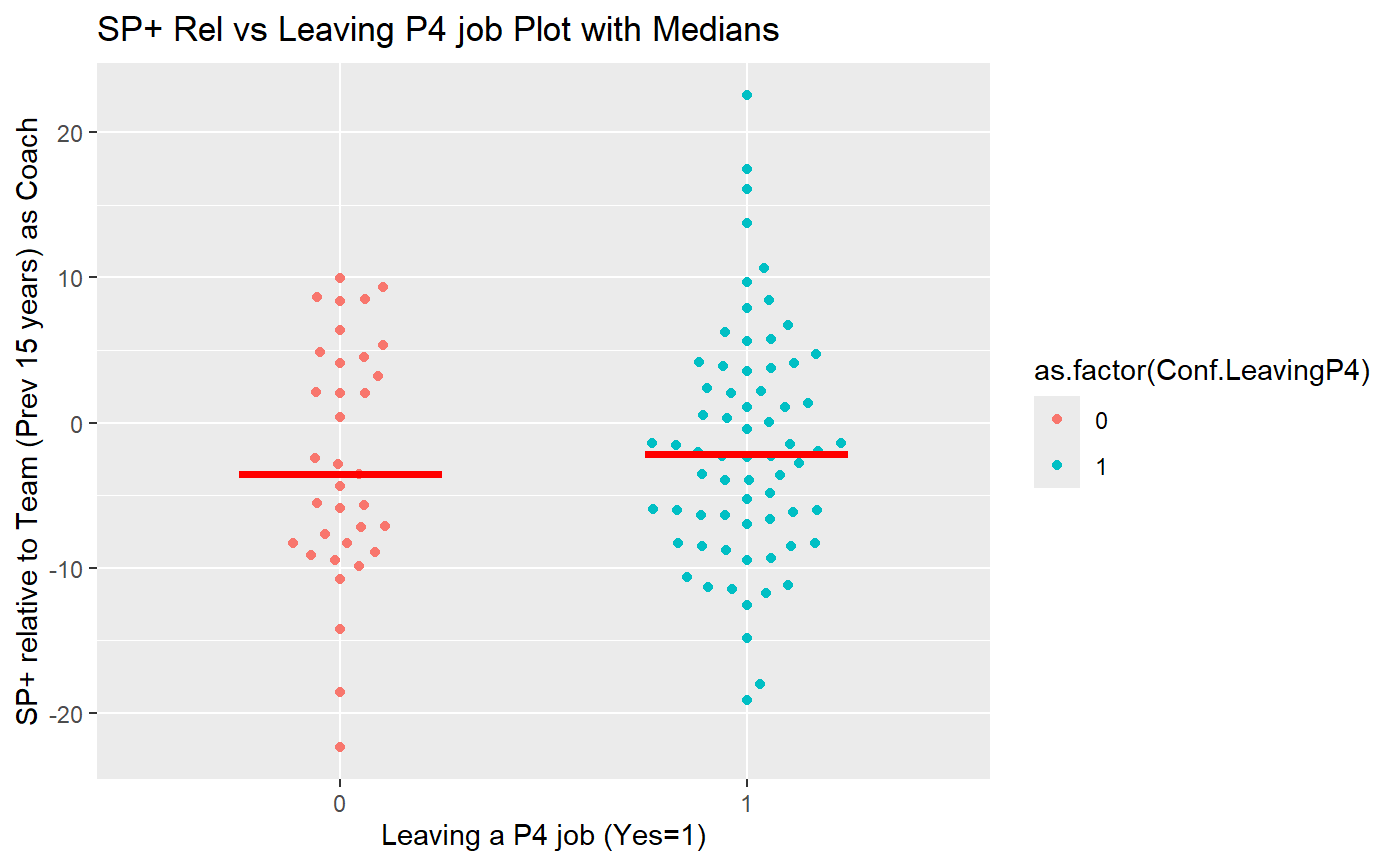</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>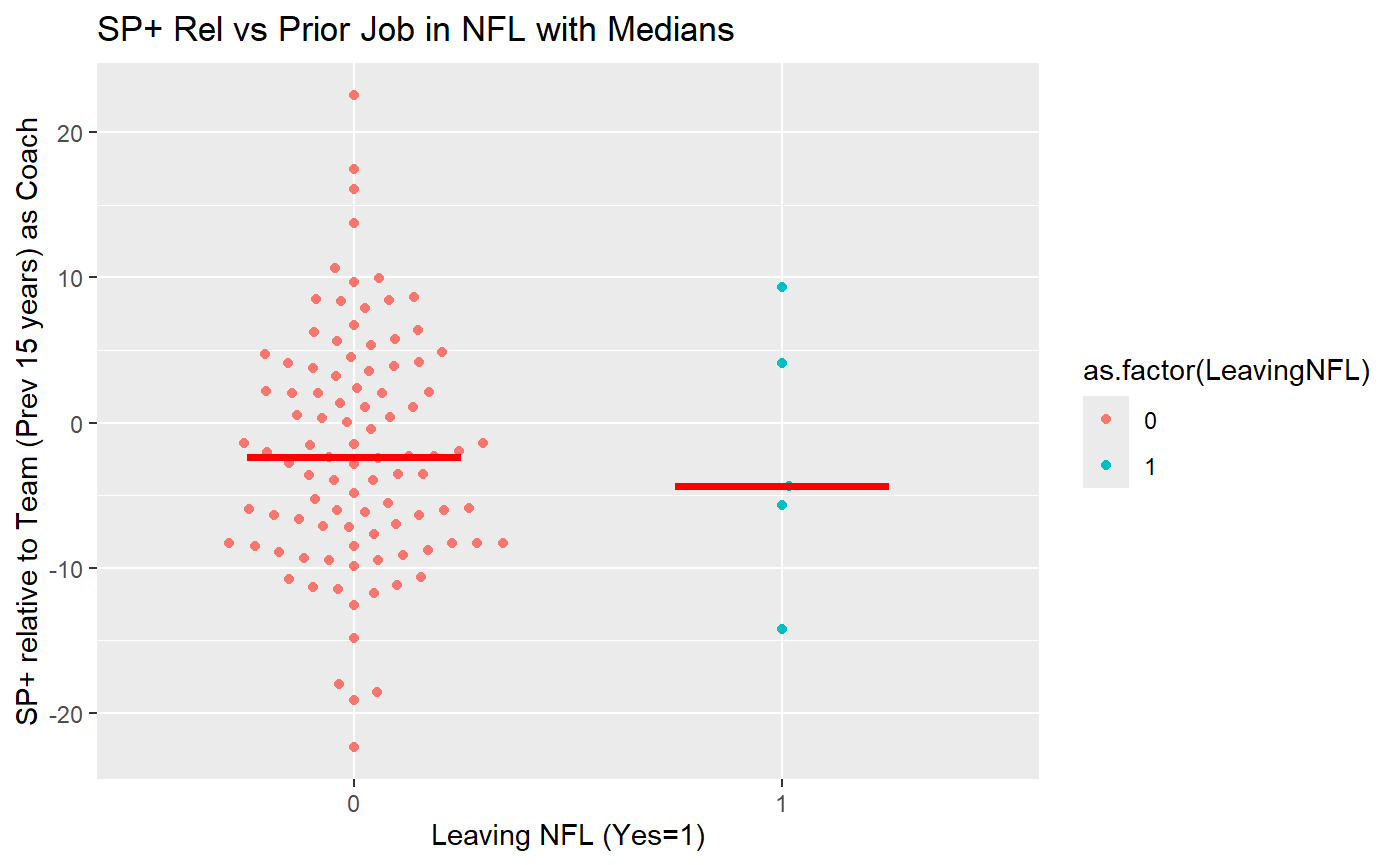</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>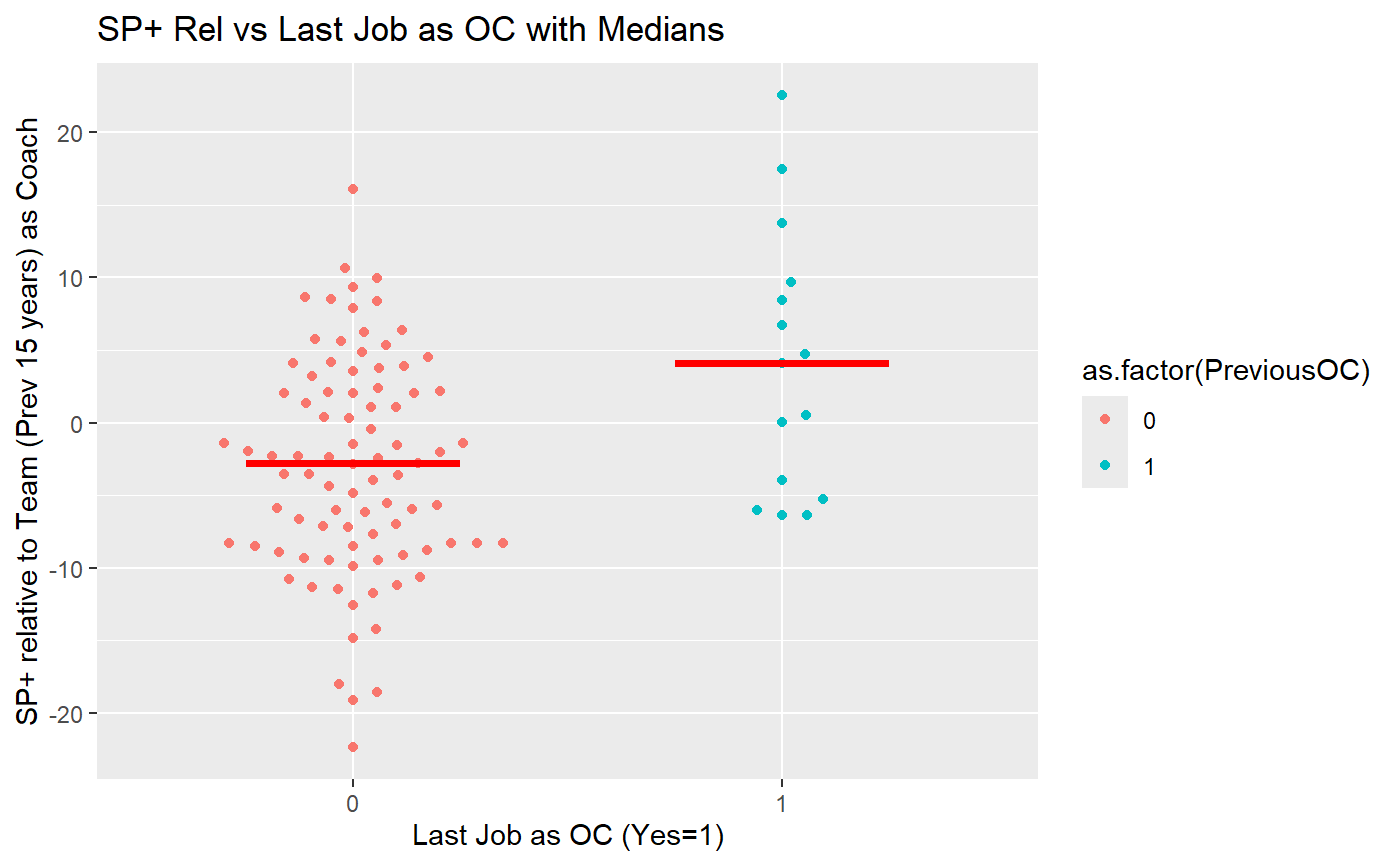</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>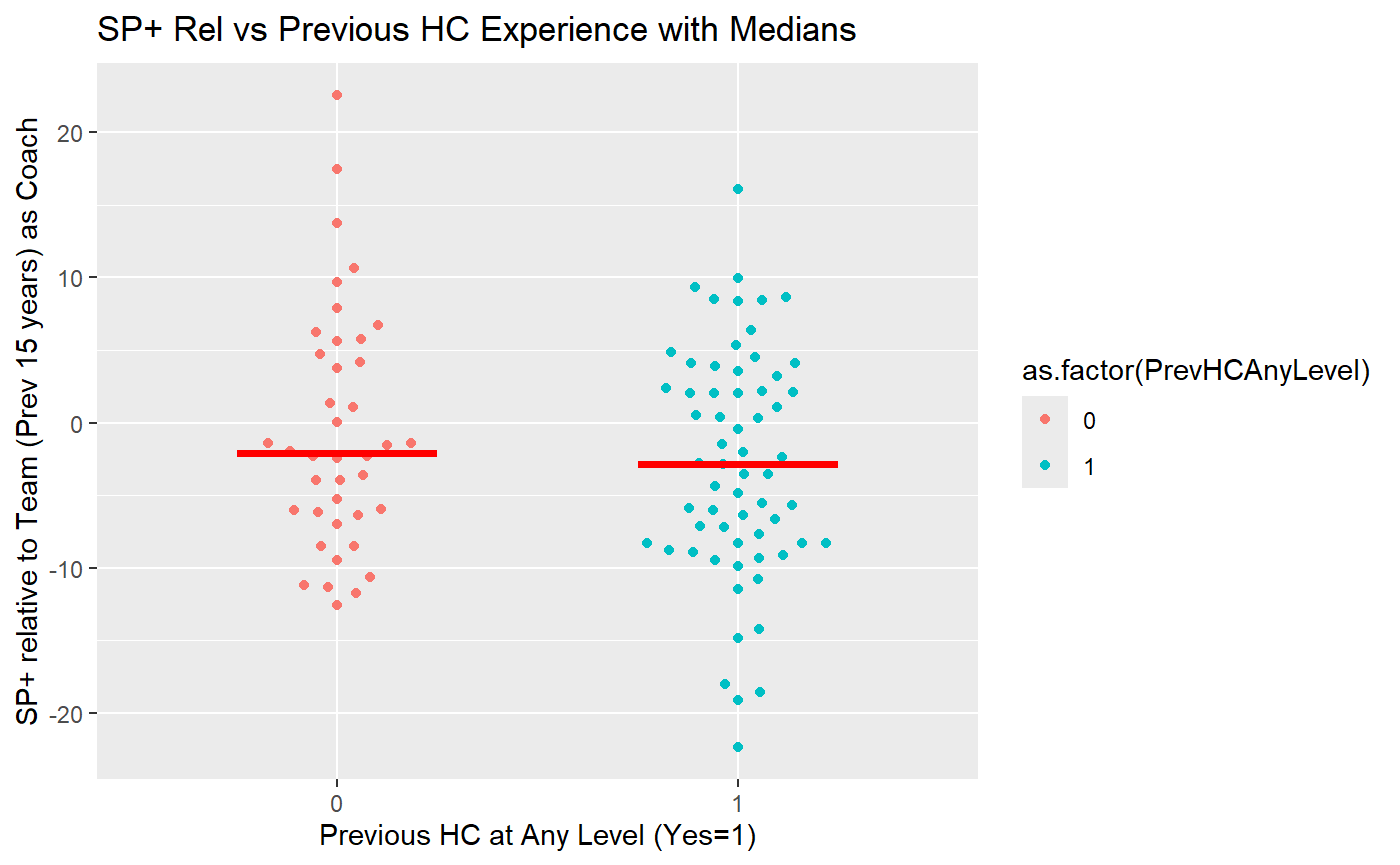</p>
</div></td>
</tr>
</tbody>
</table>

Plots for selected categorical predictors vs SP Rel +

To determine how successful each coach was as a hire we calculated their performance as a HC relative to the historical performance of the university where they were hired. For performance we considered three measurements. First we considered a hire’s win percentage since winning is arguably the most important outcome for a head coach. Second, we considered a coach’s average Simple Rating System (SRS). This metric, SRS, is a “weighted scoring margin” where the weighted part is based upon the quality of the teams that have been played \[@intro_srs\]. Third, we considered a coaches average relative SP+ which is a predictive metric developed by Bill Connelly \[@intro_sp\] that is a “tempo- and opponent-adjusted measure” of team efficiency \[@sp_2025\]. The historical values for win percentage, SRS and SP+ were obtained using the *cfbfastr* package \[@cfbfastr\]. We augmented those data with wins and losses from the 2025 season.

In [ ]:
top_coaches=coach_all_df %>%
  arrange(desc(sp_rel_team)) %>%
  mutate(Rank=1:nrow(coach_all_df)) %>%
  select (Rank,name,school,sp_rel_team, sp_rel_team_z,numb_seasons) %>%
  slice(1:10) %>%
  mutate(sp_rel_team=round(sp_rel_team,1)) %>%
  mutate(sp_rel_team_z=round(sp_rel_team_z,2)) 

bottom_coaches=coach_all_df %>%
  arrange(sp_rel_team) %>%
   mutate(Rank=nrow(coach_all_df):1) %>%
  select (Rank,name,school,sp_rel_team, sp_rel_team_z,numb_seasons) %>%
  slice(1:10) %>%
  mutate(sp_rel_team=round(sp_rel_team,1)) %>%
  mutate(sp_rel_team_z=round(sp_rel_team_z,2)) %>%
  arrange(Rank)

top_bottom=bind_rows(top_coaches,bottom_coaches)


kable(top_bottom,col.names = c("Rank","Coach","School", "SP+ Rel", "SP+ Rel Z", "Seasons as Coach"),  caption = "Top 10 and Bottom 10 Coaching Performances Based Upon SP+ Rel")

  ----------------------------------------------------------------------------
    Rank Coach           School           SP+ Rel  SP+ Rel Z  Seasons as Coach
  ------ --------------- --------------- -------- ---------- -----------------
       1 Curt Cignetti   Indiana             26.5       3.25                 2

       2 Josh Heupel     UCF                 21.1       2.59                 3

       3 Sonny Dykes     SMU                 17.8       2.18                 5

       4 Rhett Lashlee   SMU                 17.0       2.08                 4

       5 Mike Gundy      Oklahoma State      13.8       1.69                21

       6 Mike Elko       Duke                10.7       1.31                 2

       7 Dabo Swinney    Clemson             10.2       1.26                18

       8 Matt Campbell   Iowa State          10.1       1.23                10

       9 Bret Bielema    Illinois             9.3       1.14                 5

      10 Lane Kiffin     Ole Miss             9.2       1.13                 6

     108 Kalen DeBoer    Alabama            -11.5      -1.41                 2

     109 Ryan Walters    Purdue             -11.7      -1.44                 2

     110 Brent Pry       Virginia Tech      -13.0      -1.59                 4

     111 Deshaun Foster  UCLA               -13.2      -1.62                 2

     112 Jonathan Smith  Michigan State     -13.5      -1.66                 2

     113 Luke Fickell    Wisconsin          -14.8      -1.82                 4

     114 Geoff Collins   Georgia Tech       -16.3      -1.99                 4

     115 Chad Morris     Arkansas           -18.0      -2.20                 3

     116 Willie Taggart  Florida State      -19.1      -2.34                 2

     117 Troy Taylor     Stanford           -21.5      -2.64                 2
  ----------------------------------------------------------------------------


One of the significant challenges for this type of analysis is to define success. This is certainly the case here, and in no small part is due to the expectations for each school. What might be a successful record at Arizona, might not be a success at Alabama. What gets a coach an extension in College Park, might be a reason to be fired in College Station or State College. Consequently, our definition of coaching performance is relative (to team history) rather than absolute.

For relative performance, we took the trimmed mean \[ ‘mean(x,trim=0.1)’\]{style=“font-family: ‘Courier New’;022} in R) of the middle 80% of years of the performance metric for their time as a head coach and subtracted the team average of that same metric for the fifteen years before the coach was hired. We chose to use SP+ as our measure and we refer to *SP+ Rel* as our outcome variable below. Note that the correlation between SRS relative to past team performance and SP+ relative to past team performance was 0.95, results using the former as a response are likely to be very similar to those for the latter and so we did not consider models with different responses. The correlation between *SP+ Rel* and a winning percentage relative to past teams was 0.82.

Using the R package *cfbfastr*, we obtained historical team data including wins and losses through the 2024 season as well as SRS and SP+ ratings into the 2025 season. We manually added wins and losses for the 2025 season. All of these data can be found at: <https://github.com/schuckers/cignetti-noise-paper>. Data on coaching performance is complete through midday on November 13, 2025.

Among these 117 college football head coaching hires in our data, there were 58 who left a job as head coach (HC) at another school, and 73 of our hires had been a HC at some level previous to their being hired. Thirty of the hired coaches had been Defensive Coordinators (DCs) and 17 were Offensive Coordinators (OCs). The other previous positions included four position coaches, an offensive analyst, four Associate or Assistant HCs and one hire who was not employed in football. While more coaches were hired directly from DC positions, 45 of the 117 hires (38%) had defense as their background. Seventy-three (73 of the hires had been a head coach at the college or NFL previously, while 26 had previously coached in the NFL. Thirty percent of the coaches were hired to jobs within the same conference. Only 18 of our hires were promoted from the coaching staff of the same institution. The average age of our coaches when they were hired is approximately 47 years.

The majority of hired coaches, 74, had not worked for, played at or attended the school that hired them. While the vast majority of the hired coaches played college football, just under 50% of them, 56, played for a P4 school and only 12 played in the NFL.

Below when we refer to recent metrics we will be talking about a five year period and when we refer to previous metrics we will be talking about a 15 year period.

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>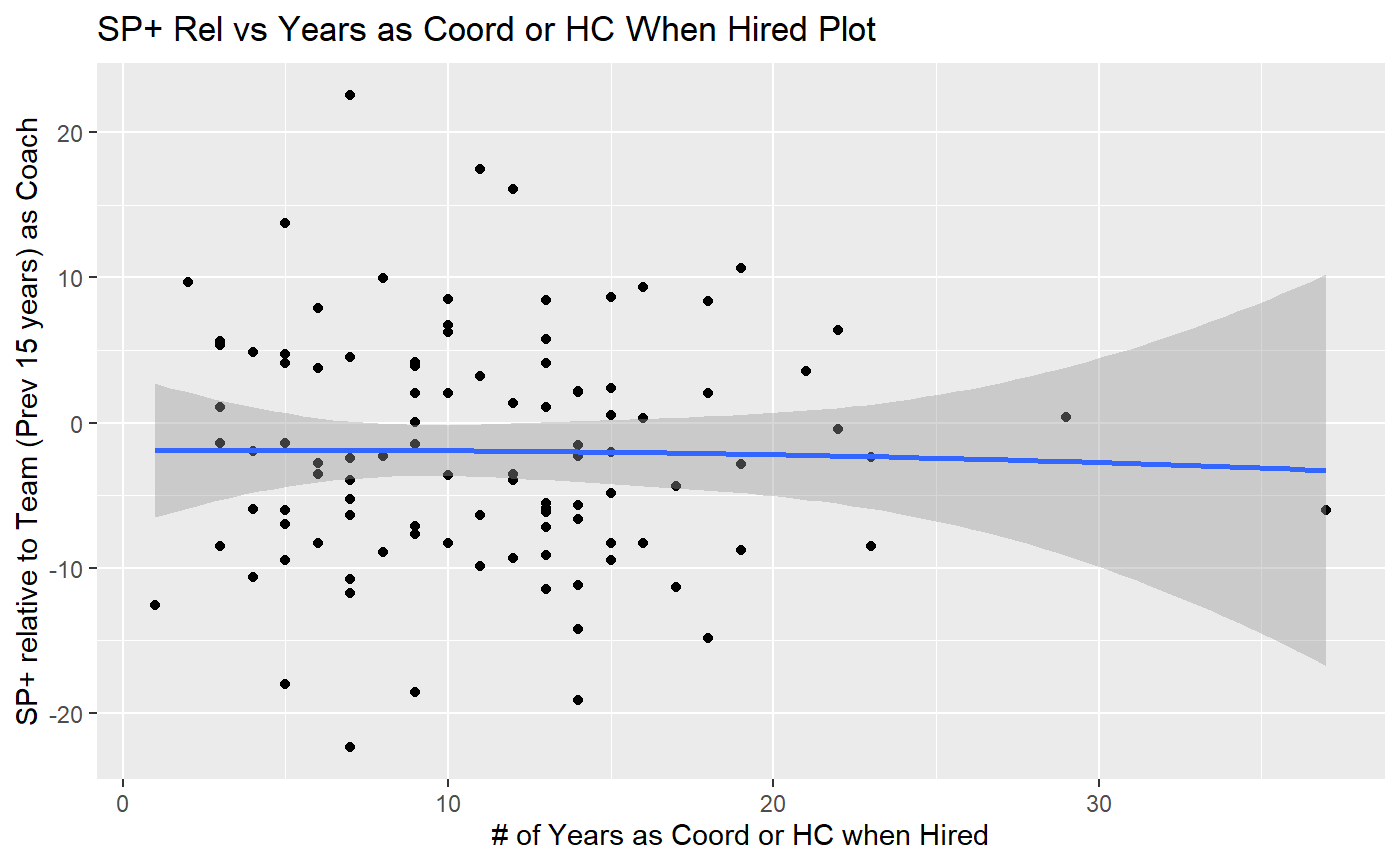</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>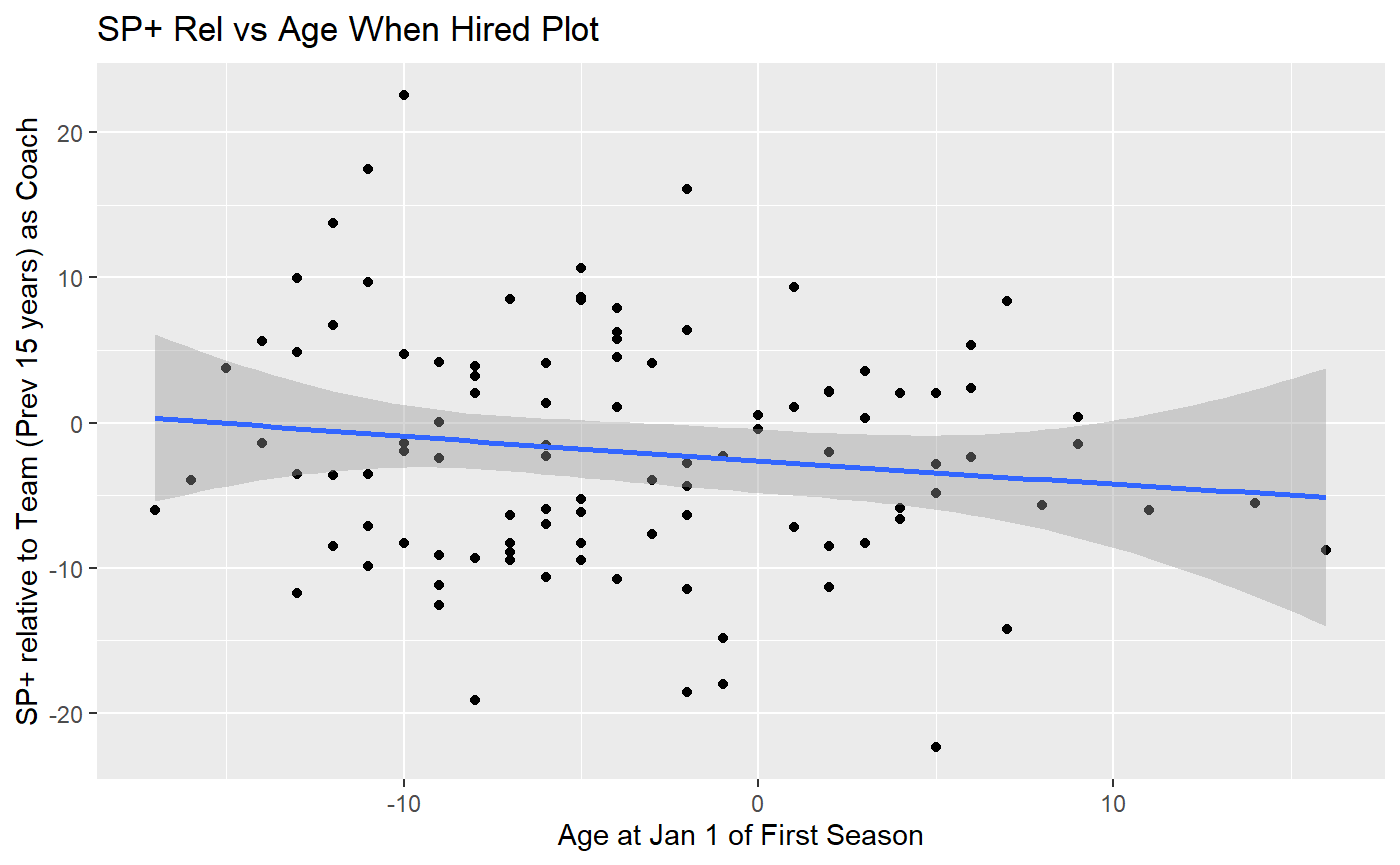</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>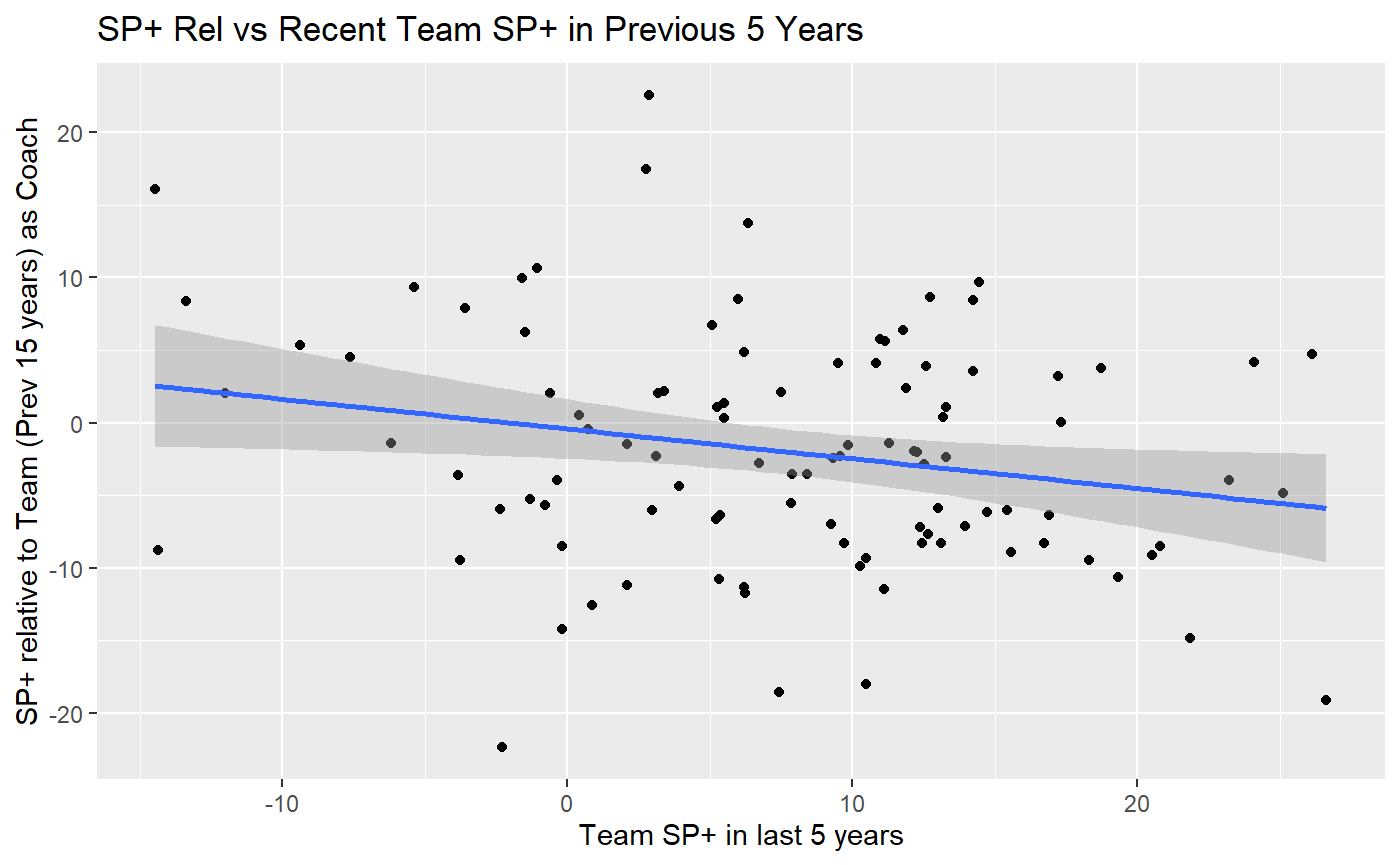</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>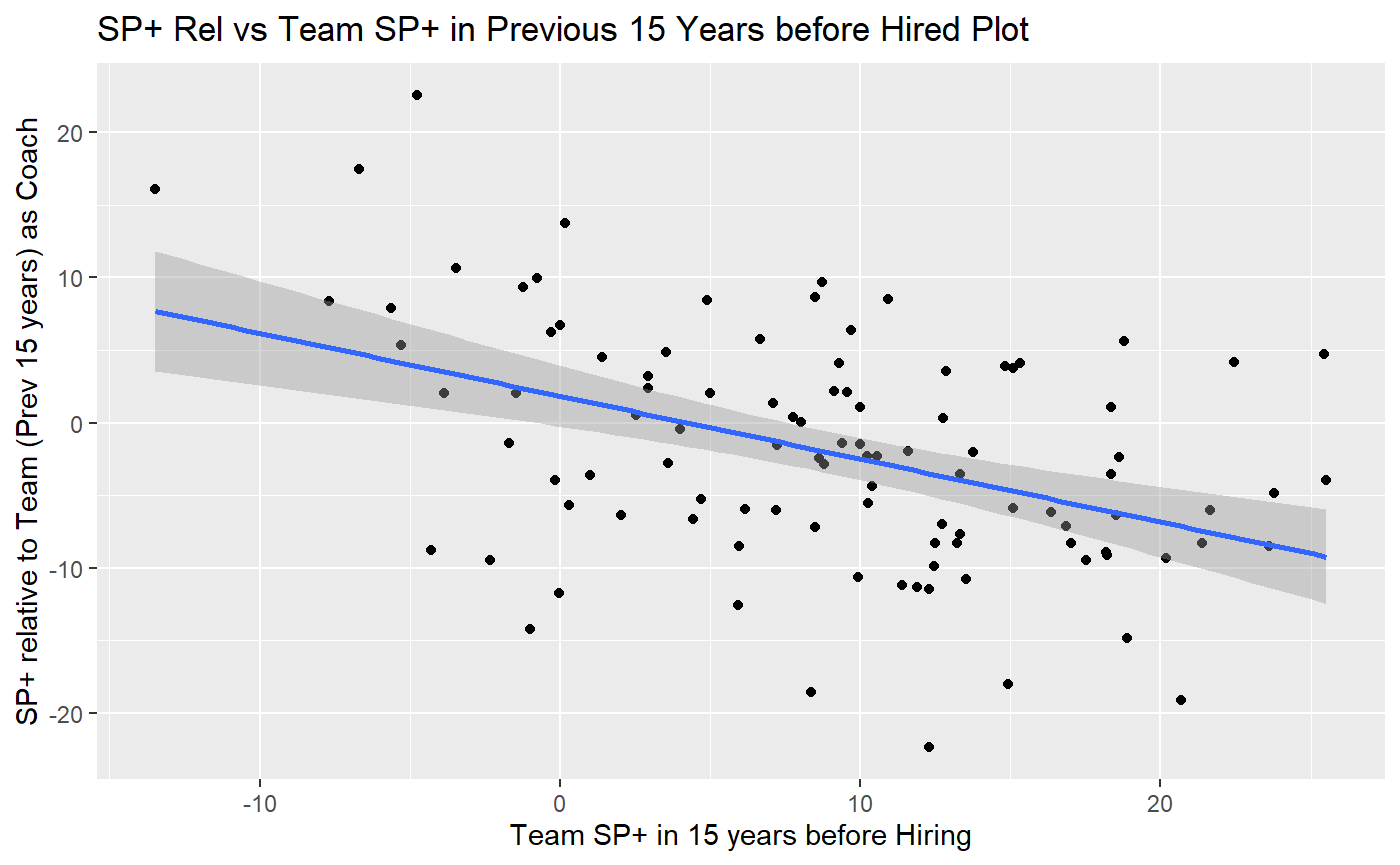</p>
</div></td>
</tr>
</tbody>
</table>

Plots for selected numeric predictors vs SP Rel

Next we will look at some of relationship between our variables and our measure of coaching performance, *SP+ Rel*. @tbl-var contains the list of predictor variables as well as their definitions. Turning to the graphics, we see a sampling of these relationship in @fig-cat1. In that figure, we can see that medians (red lines) seem to indicate there are some differences between the categories for winning a national championship as a coordinator, @fig-prev-nc, and for previous job was as an OC, @fig-oc. Otherwise the other variables do not seem to suggest there is much difference in the typical coaching performance for the different characteristics recorded in those subfigures. More graphics like these can be found for the other categorical predictors in @fig-append-cat and @fig-append-cat2. In those graphics, @fig-append-cat (d) suggests that having played in the NFL yields a higher median *SP+ Rel* as does having previously won a national championship as a coordinator, @fig-append-cat2 (b). However, quite a bit fewer coaches have the value that is associated with the higher median.

Turning to numeric predictors, we can see the relationship between *SP+ Rel* and four of these predictors in @fig-numeric1. In @fig-yrs-coord, we can see that there is not a relationship between number of years as a HC or Coordinator before being hired. The three remaining subfigures, @fig-age, @fig-sp-recent, @fig-sp-prev15, also show negative linear relationships between *SP+ Rel* and coach’s age, teams performance in the recent past, 5 years, and team performance in the previous 15 years. More figures like this can be found in @fig-append-numeric of the Appendix at the end of this report. Noteworthy among those figures in the Appendix is that there seems to be a positive linear relationship between a hired coach’s *SP+ Rel* and their previous *SP+ Rel* had they been a college HC previously.

# Model and Results

The goal of this analysis is to build a predictive model for the success of a coaching hire and to identify the factors that impact that success. We selected 29 predictors found in @tbl-var that could be useful for predicting coaching success. For our model formulation, we chose to build a regularized linear regression model for SP+ relative to past team performance, hereafter *SP+ Rel*. We used `cv.glmnet` as part of the `glmnet` library in R \[@glmnet\]. For our regularization, we considered both ridge and lasso regression, and we used 8-fold cross validated performance to determine the regularization/shrinkage parameter, $\lambda$, for our model. We ran 20 different randomizations of 8-fold cross validation. Consistently, across all these different randomizations of the folds, we found that the best lasso model had a smaller out of sample prediction error (via MSE) than the best ridge model. To get the parameter coefficient estimates discussed below we fit the full model via a lasso with $\lambda$ set to the average of the shrinkage parameters that minimized the cross-validation error. In fact there was no variability in these shrinkage parameters across the 20 randomizations. Because some of our predictors, e.g. `sp_prev_rel`, were available only if a coach had previously been a college HC, we included whether or not a coach was previously an HC in all of the models we considered.

Our final prediction equation is:

{#eq-predictioneq}

The largest factors in our model were whether or not the coach’s previous job was as an OC (`PreviousOC`), whether they had ever been a college coach previously (`prevCollegeHC`) and the team’s performance over the last 15 years (`team_sp_prev`). Having been hired from an OC position is associated with about a $2.37$ point increase in a coach’s *SP+ Rel*. While if a hire was previously a college football HC, the predicted decrease in their team’s performance is fourth-tenths a point. The last term in our prediction equation involves a team’s average *SP+ Rel* over the previous 15 years and that is negatively associated with how a coaching hire’s teams will perform. We can interpret the value here of $-0.34$ as the expected decrease in a team’s average performance for every additional point of *SP+ Rel* that the hiring team had over the previous 15 years. This is a regressive effect, since SP+ for an average team should be around zero, then for a new coaching hire, good teams we would expect them to get worse and very good teams we would expect them to get much worse, while for below average teams we would expect them to get better just by making the hire. One possible explanation for this is a regression to the mean as team performance tends to move to the average of all teams, which for SP+ is around zero. Another explanation is college football has moved to an era of more parity and relative coaching performance is not immune to moving with that trend.

The hires with the ten highest and ten lowest predicted *SP+ Rel* are listed in @tbl-top-bottom. We can see that the model suggests that the hire with the highest predicted success was Rhett Lashlee at SMU. Eight of the ten top predicted *SP+ Rel* values had positive observed values. Tony Elliott at Virginia and Jedd Fisch at Arizona were the exceptions. Elliott has improved his Virginia teams and, if he stays, may yet get to positive territory. Fisch left Arizona after a successful second season. Among the coaches predicted to have negative *SP+ Rel*, eight of the ten are in or have finished in negative territory. The exceptions are Dan Mullen whose team performance dropped significantly over his four years at Florida and Kirby Smart who has impressively elevated Georgia to new heights. Seven of these ten coaches have already been fired with only Smart, Fickell and Venables still employed at these schools. Venables’ Oklahoma 2025 team had one of their best recent seasons with him as a HC and so there is hope for a turnaround there. Looking at the bottom ten schools, most of the schools there are considered to be ‘elite’ or nearly so. The model predicts that succeeding at these schools is hard partly because they are already at the upper tail of the distribution. Overall the model accurately predicts whether a coach will have a positive or negative *SP+ Rel* 67% of the time.

The model we have explains about $15\%$ of the variability in the team’s performance with a newly hired coach and the average difference between our model’s prediction and the actual *SP+ Rel* of the coaches in these data is just over $7.5$ points. That is a large amount of variability and it speaks to the noisiness of these data. However, the model does well given that noisiness at predicting who will have a *SP+ Rel* above or below zero achieving 68% accuracy on this metric.

While it is important to focus on the factors that do influence hiring success, it is worth mentioning those that do **not** given the factors that **are** in the model. Having a previous connection to the school, being a previous head coach at any level, having NFL coaching experience, having experience as a recruiting coordinator, having played football in the NFL or at a P4 school seem to have no impact on our ability to predict how well a coach will do. Winning a national championship as a HC at any level as well as being a Coordinator for a team that won a national championship or a conference championship does not predict coaching success. Similarly having regional ties to the hiring school does not seem to be impactful and the same is true for moving within the same conference or leaving a P4 school. A coach’s relative SP+ as a previous HC is also not predictive, as is their previous win percentage. One possible explanation is that we are taking averages of previous coaching performance that misses changes in SP+ over a coach’s time with a previous school, e.g. Matt Rhule at Temple and Lance Leipold at Buffalo. Finally, the number of games coached as an HC before being hired is unimportant as a predictor as is the recent winning percentage of the team.

# Discussion

Choosing a successful P4 college football coach is a difficult task. In this paper we have collected data on recent P4 coaching hires and built a predictive model for their performance. The data we used was on recent P4 hires and we measured their performance using average SP+ relative to previous performance of the school’s teams, *SP+ Rel*. As mentioned above *SP+ Rel* is correlated with a coach’s winning percentage and highly correlated with their SRS, the other statistical measure of team performance that we considered.

Ultimately, we found that there are several factors that are predictive of the performance of a college football head coaching hire. These factors include whether a hire had been a previous college coach, whether the hire had previously won a conference championship as a coach, whether their prior job was as an offensive coordinator, their age and the quality of the team they were hired to lead over the previous 15 years. Our prediction model does not perform particularly well, only explaining just under a quarter of the variability in coaching performance.

The 2020 season is among the years in these data. The effects of COVID were felt across college football in the form of shortened seasons and empty stadiums. Every school and every conference handled the situation differently. One of the choices we made as part of this analysis was that we would keep the 2020 season in our data. Given the short tenure of some college football head coaching hires, we felt having as much data as possible was important.

This study measured the success of a coaching hire by how they did on average relative to their team’s previous 15 years. That is not a perfect measure. Team performance fluctuates and trends, sometimes upward and sometimes downward. Ideally when a new coach is hired their teams trend upward as they recruit players that fit their system and they become comfortable in their new job. An average over a short period may miss this effect. That said, it is very difficult to generate a measure of coaching success that captures all of the possible nuances. Therefore, we chose to stick with an average relative to past team performance.

Much has been made about the recent success of Curt Cignetti and he has done an amazing job as the HC at Indiana. Cignetti is an outlier. It is very clear which observations corresponds to the exceptional job Cignetti has done at Indiana. That said, an outlier is not a trend and the signal from these data is weak. Hiring a coach is hard; hiring a really successful coach is *very* hard. There are no magic attributes, at least *not* among the factors we investigated, that guarantee future success. The data as can be seen in @fig-cat1 through @fig-append-numeric is very noisy and the trends, while tempting, are mild. Great coaches are hard to find and many schools find themselves having difficulty distinguishing the Cignetti’s from the noise.

The code and the data for the analyses presented here can be found at <https://github.com/schuckers/cignetti-noise-paper>.

Thanks to the team who put together `cfbfastr` for making their data available in a usable and regularly updated manner and to Brian Macdonald (Yale) for thoughtful discussions about this analysis.

# Appendix

| Variable Name | Variable Meaning |
|:-----------------------------------|:-----------------------------------|
| `prevCollegeHC` | Were they previously a college head coach (HC) |
| `PreviousHC` | Was job when hired as a HC |
| `PreviousOC` | Was job when hired as an Offensive Coordinator (OC) |
| `PreviousDC` | Was job when hired as a Defensive Coordinator (DC) |
| `Conf.LeavingP4` | Was job when hired at P4 school |
| `SameConf` | Was job when hired in same conference |
| `AgeAtHiringMinus50` | Age on Jan 1 of first season as HC |
| `ConnectionToHiring.School` | Had coach previously played or been employed at hiring school |
| `NFLCoachingExperience` | Had the coach ever coached in the NFL |
| `RecruitingCoord` | Previously been a recruiting coordinator or not |
| `PlayedNFL` | Had coach played in the NFL |
| `Played.Power.4` | Had coach played at a Power 4 school |
| `WonNCasHCany` | Had coach won a National Championship (NC) as HC at any level (college) |
| `WonCCasHCany` | Had coach won a Conference Championship (CC) as HC at any level (college) |
| `WonNCasCoordAny` | Had coach won a NC as an OC, DC, or AHC at any level (college) |
| `WonCCasCoordAny` | Had coach won a CC as an OC, DC, or AHC at any level (college) |
| `SideO` | Is coach’s primary background on Offense |
| `LeavingNFL` | Was previous job in the NFL |
| `Regional.Ties` | Had coach previously worked within 500 miles of hiring school |
| `numb_years_Coord_adj` | Number of years as OC/DC/AHC/HC above average of 11.8 years |
| `numb_years_Coord_HCadj2` | Numbers of years as OC/DC/AHC/HC different from 11.8 squared |
| `PromoteWithin` | Coach was promoted to HC from other position at same school |
| `NumberPriorStops` | Number of different teams coach worked for before being hired |
| `AllPriorWinPct` | Win Percent as Coach at all levels before being hired |
| `winpct_prev_Rel` | Win percent as HC at previous job |
| `team_sp_prev` | Hiring school’s SP+ in 15 years before hire |
| `team_sp_recent` | Hiring school’s SP+ in 5 years before hire |
| `GamesAsHCPrior` | Number of games as a HC before being hired |
| `team_winpct_recent` | Hiring School’s win percentage in the last 5 years |
| `sp_prev_rel` | Previous *SP+ Rel* in HC role |

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>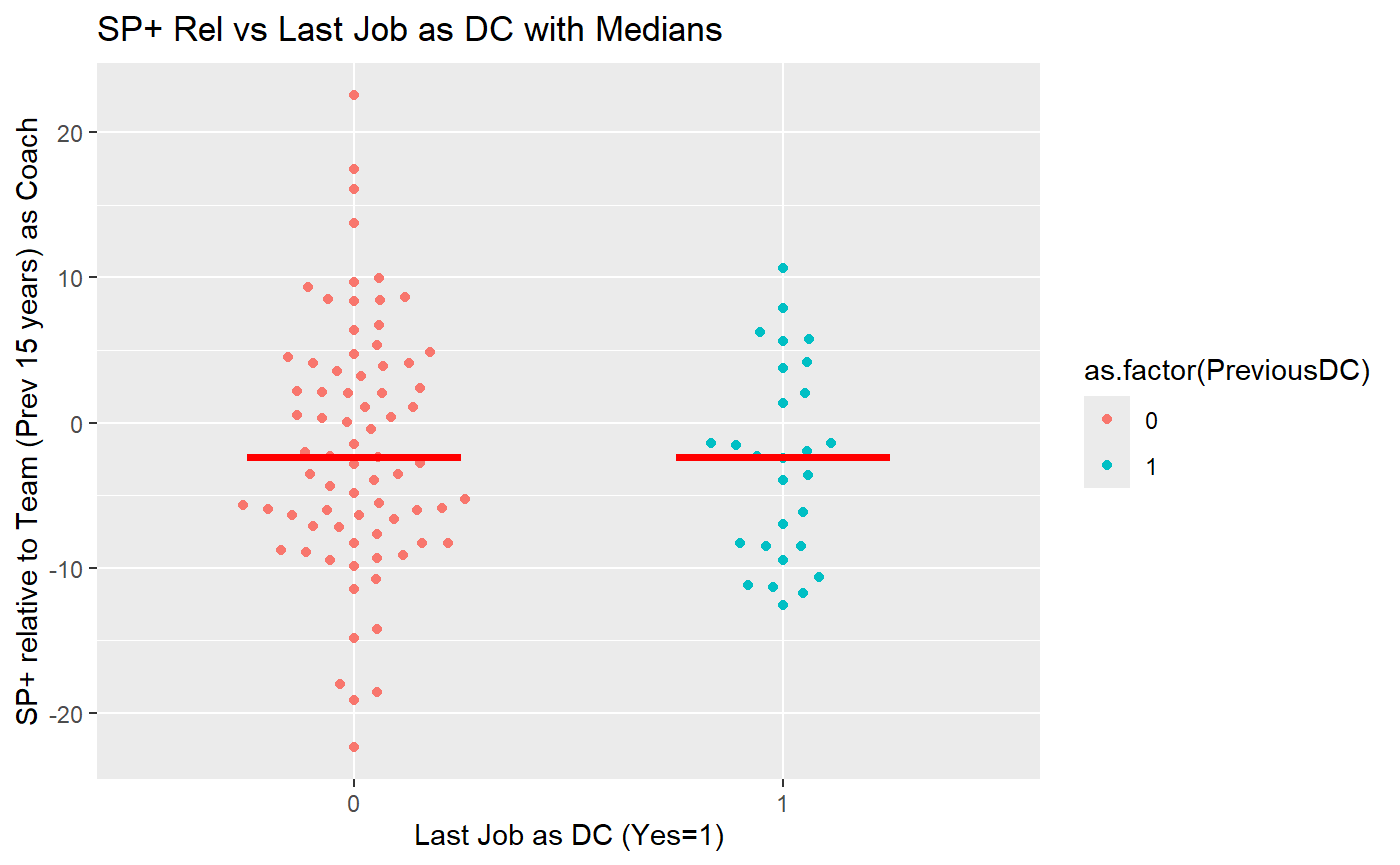</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>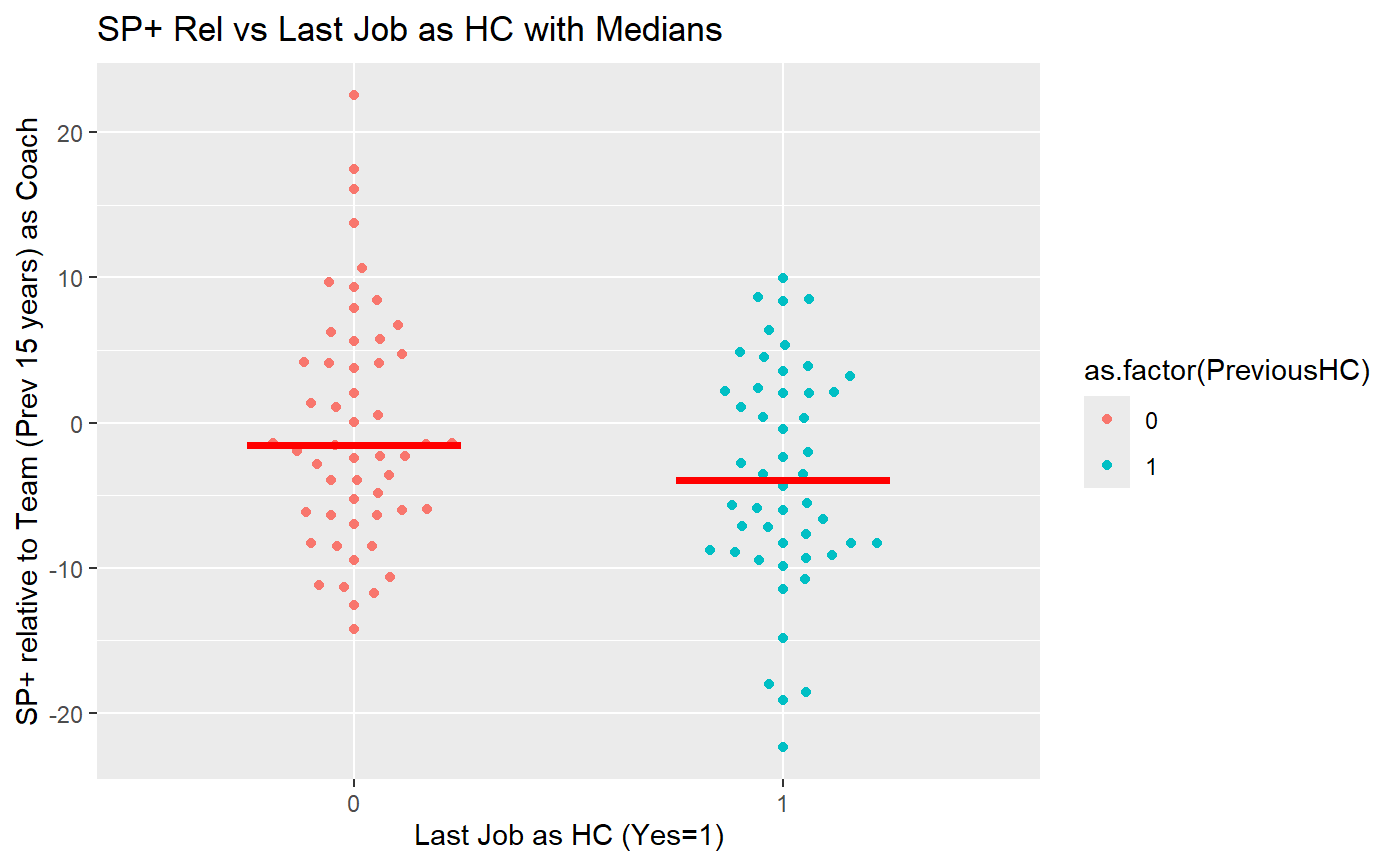</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>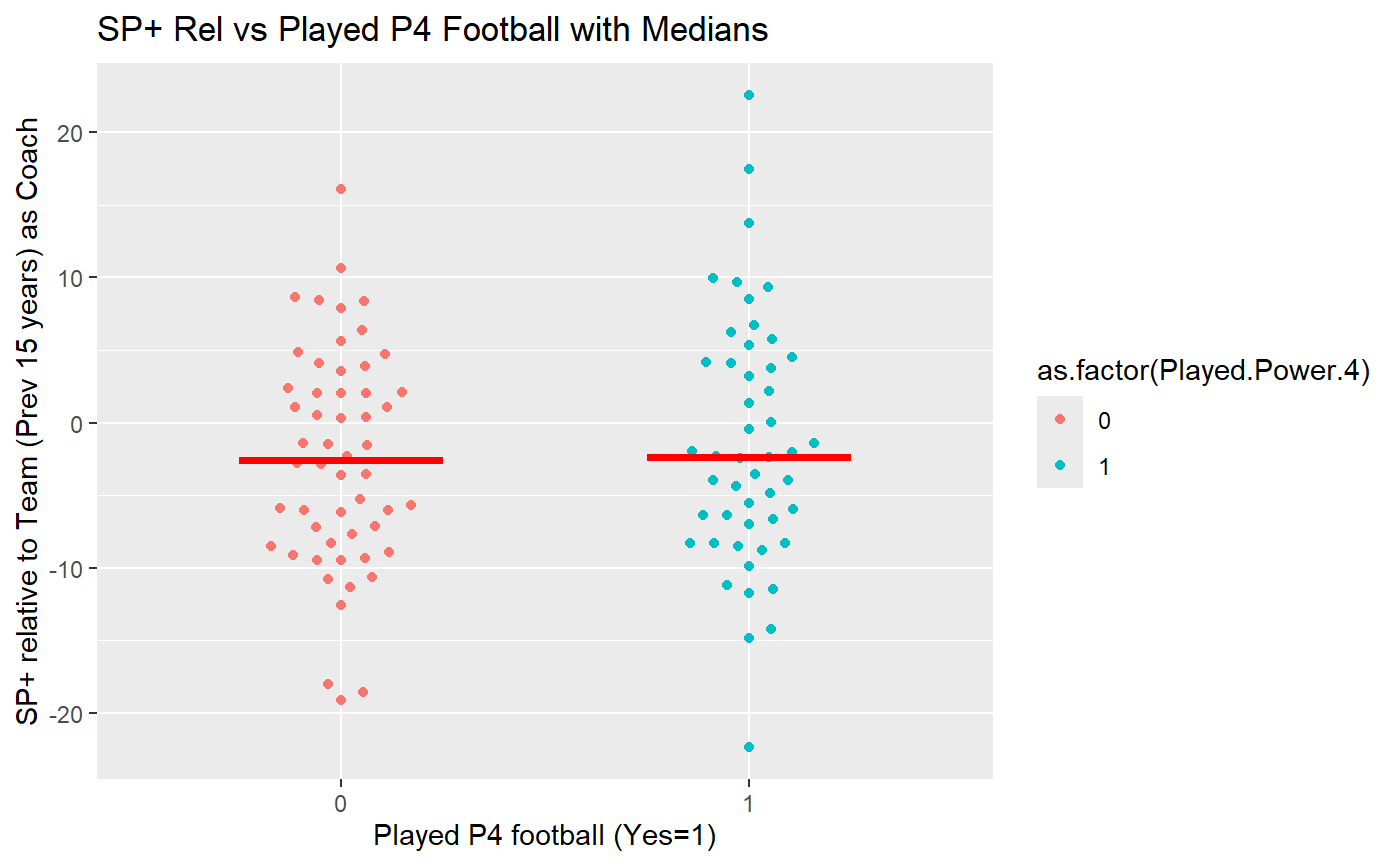</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>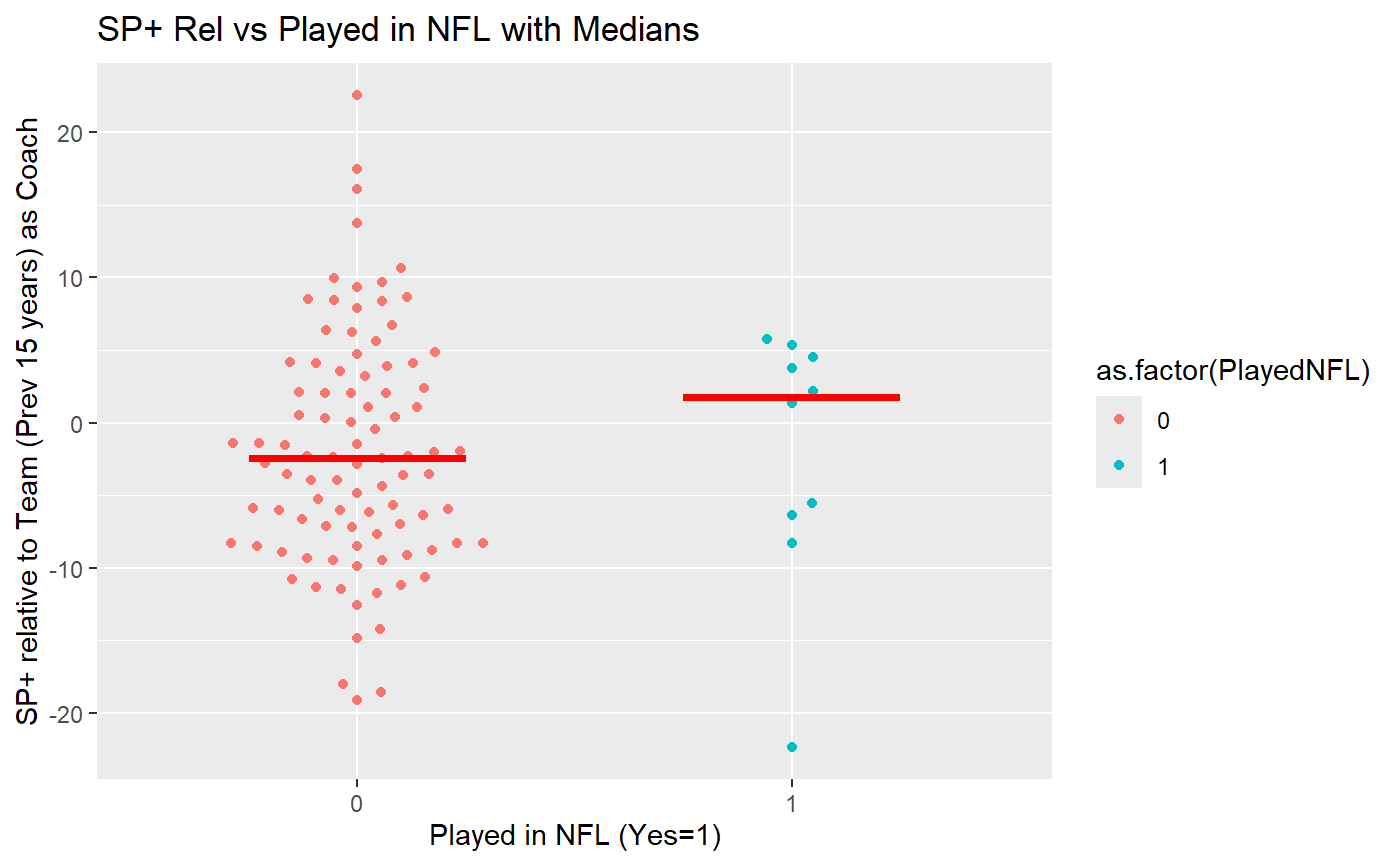</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>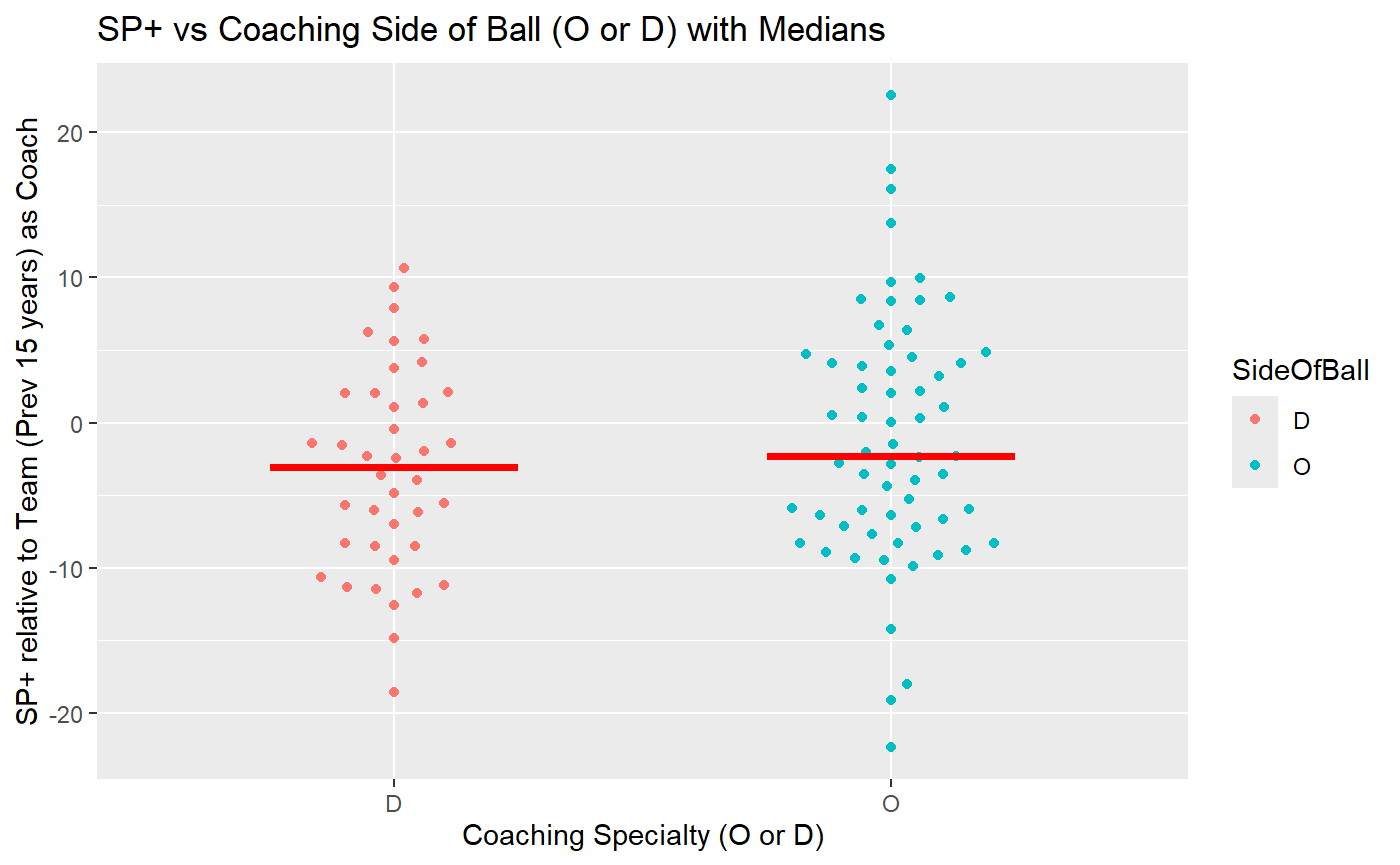</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>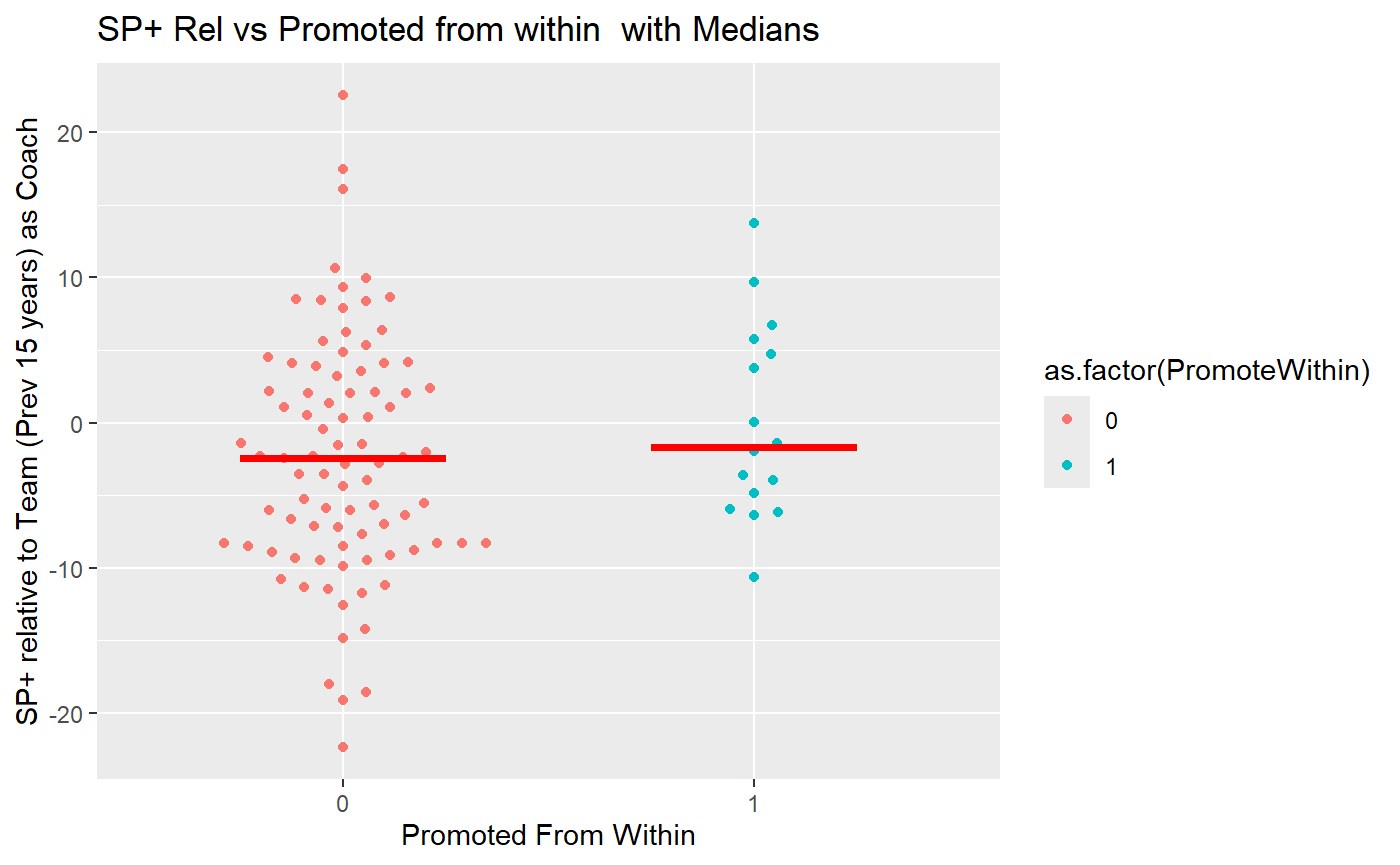</p>
</div></td>
</tr>
</tbody>
</table>

Additional plots of categorical predictors vs *SP+ Rel*

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>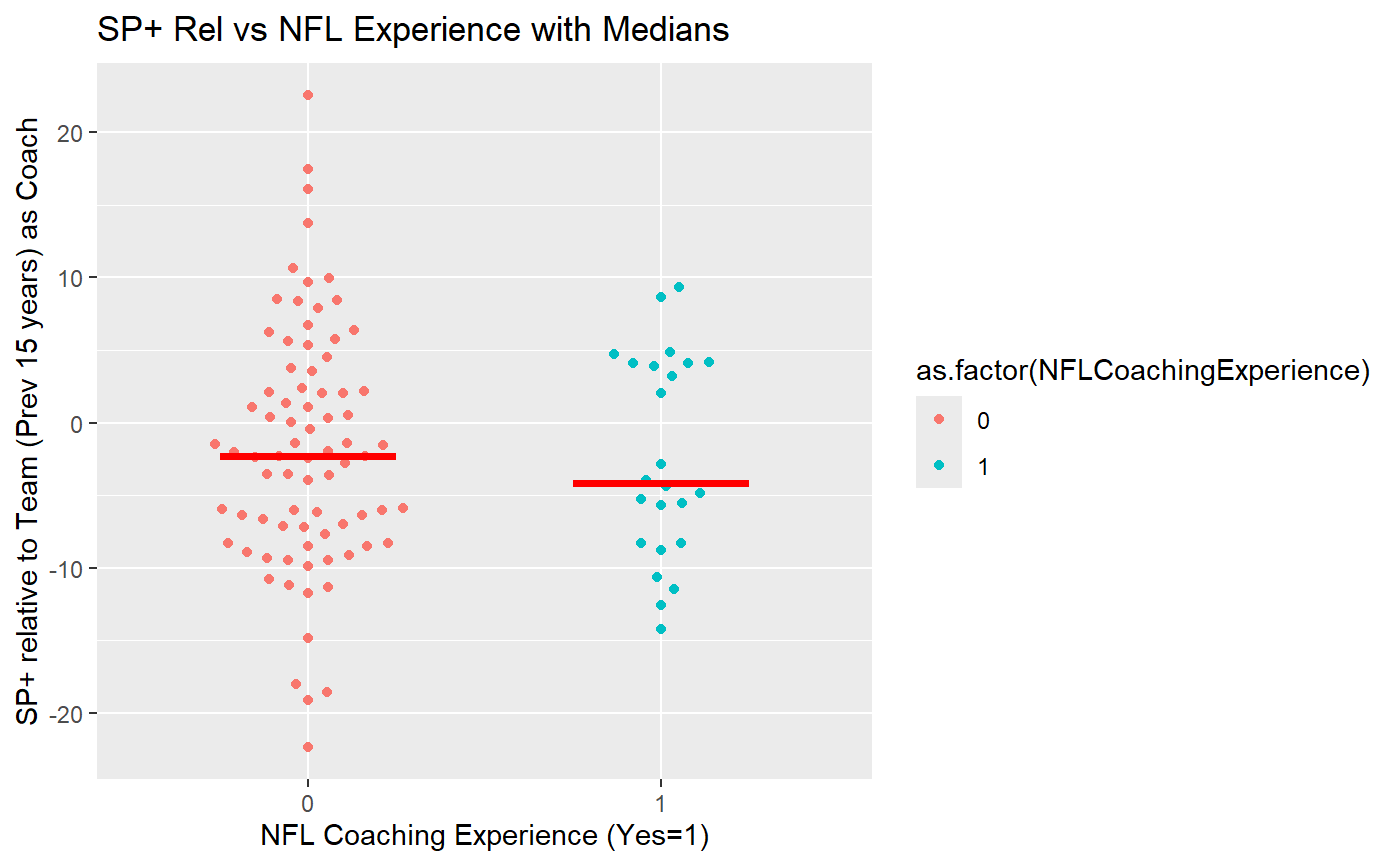</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>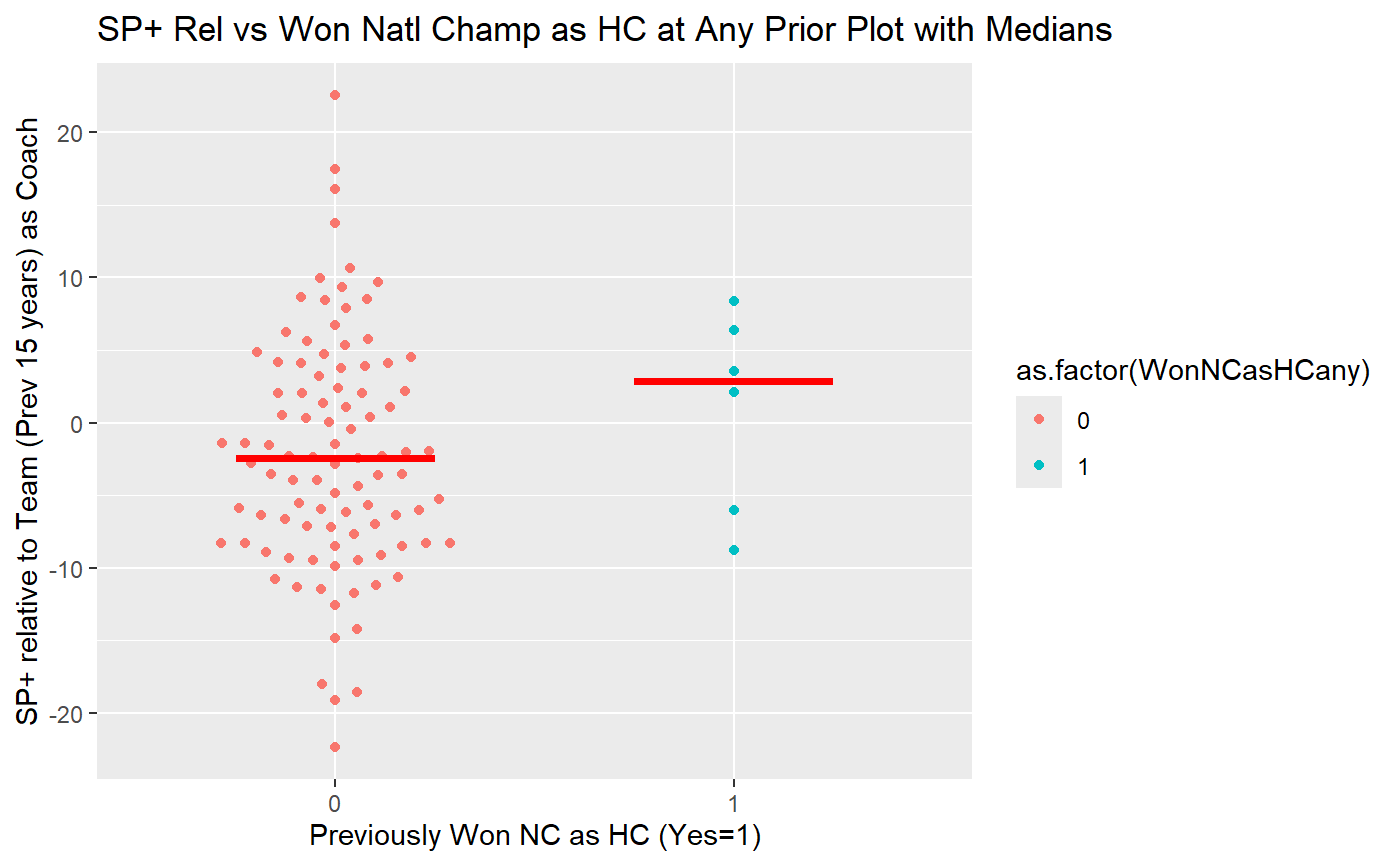</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>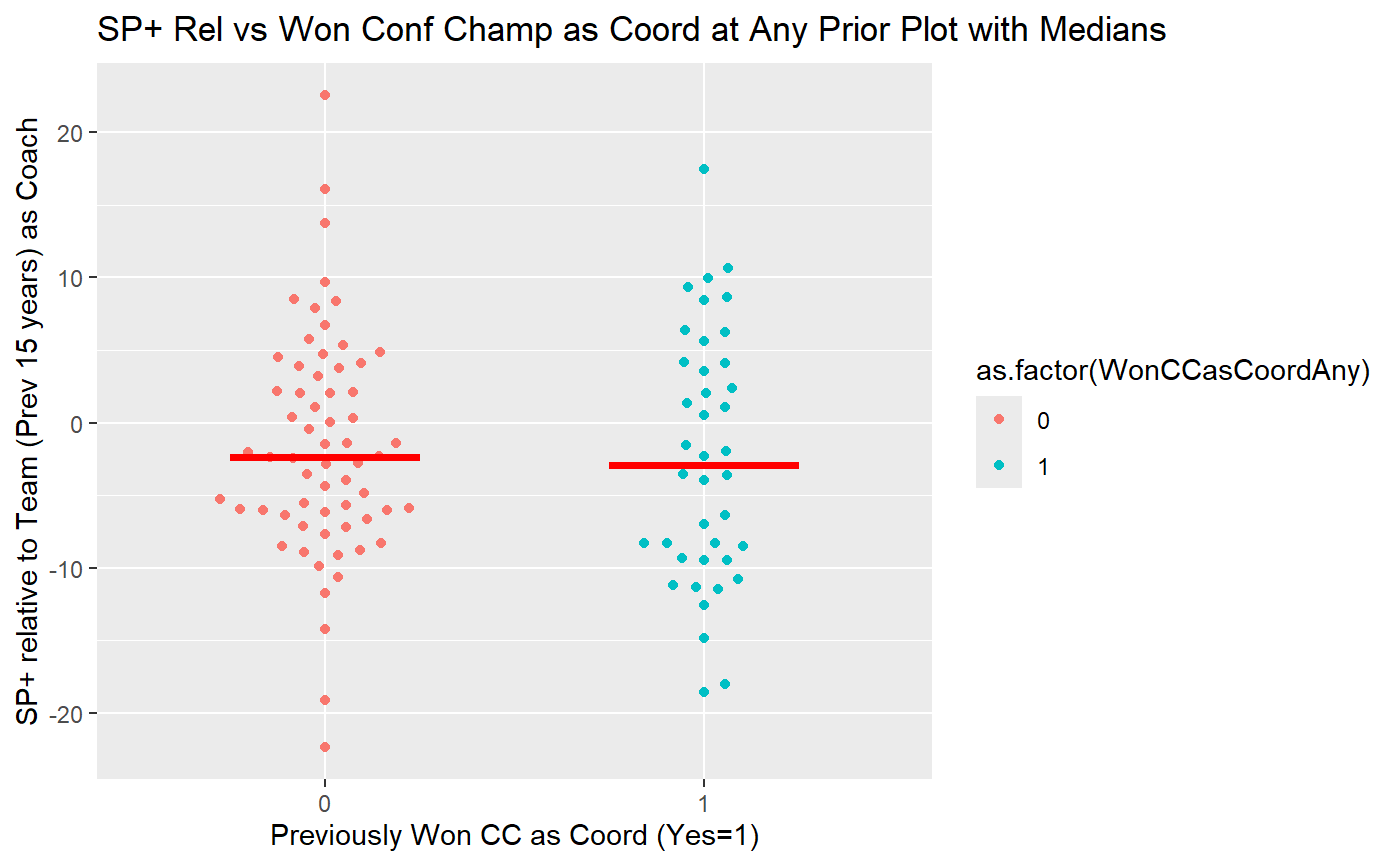</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>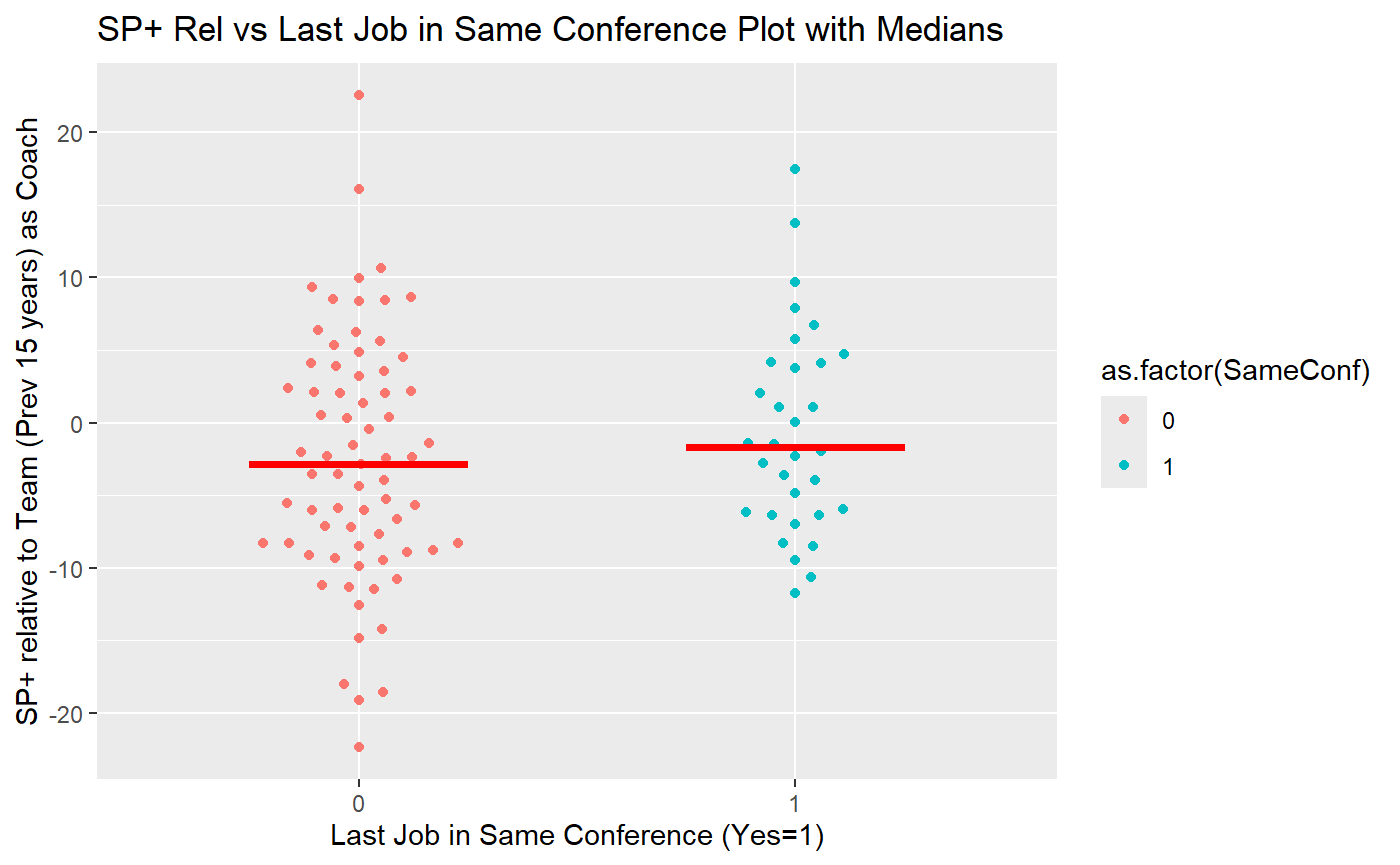</p>
</div></td>
</tr>
</tbody>
</table>

<table style="width:50%;">
<colgroup>
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>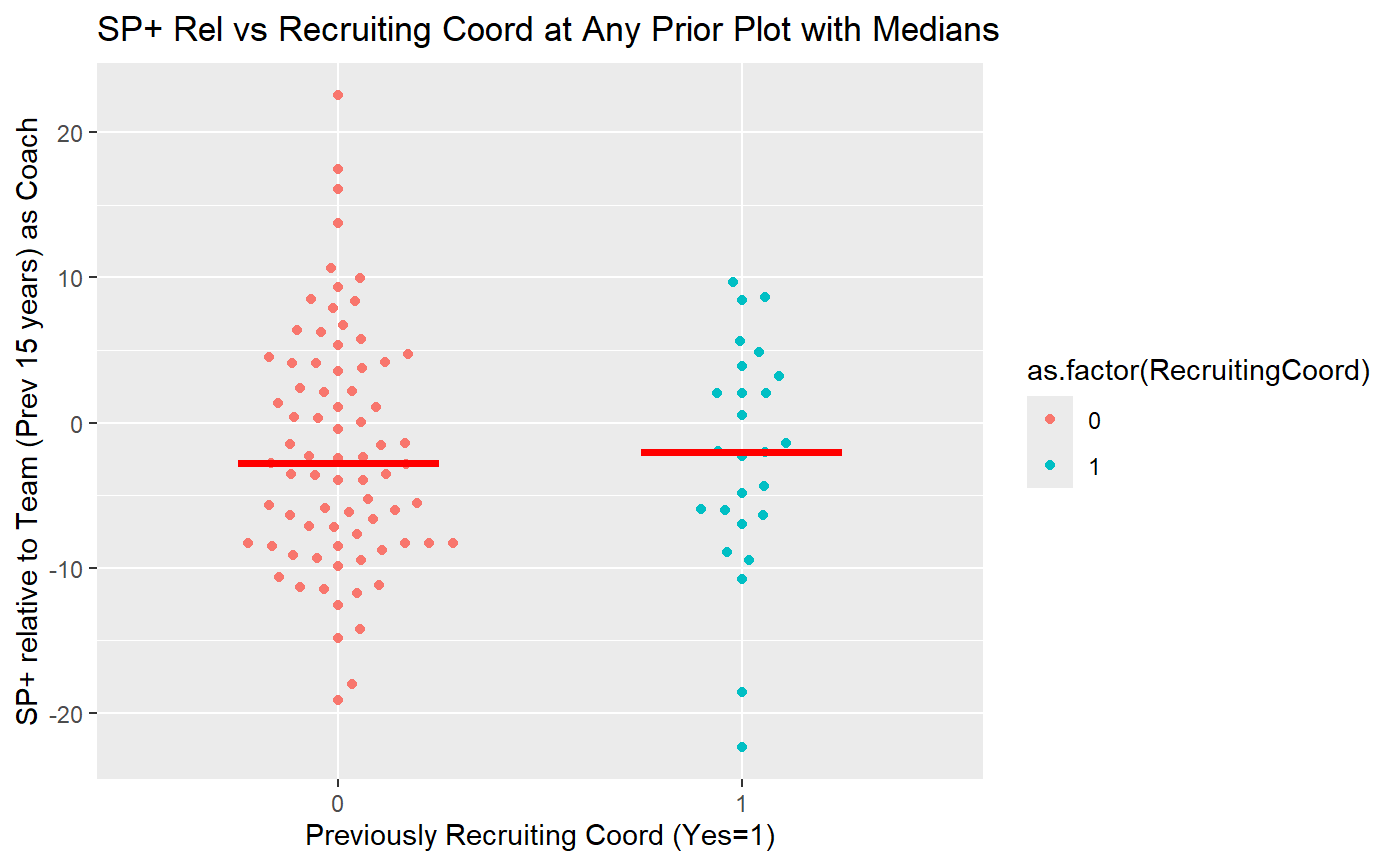</p>
</div></td>
</tr>
</tbody>
</table>

Additional plots of categorical predictors vs *SP+ Rel*

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>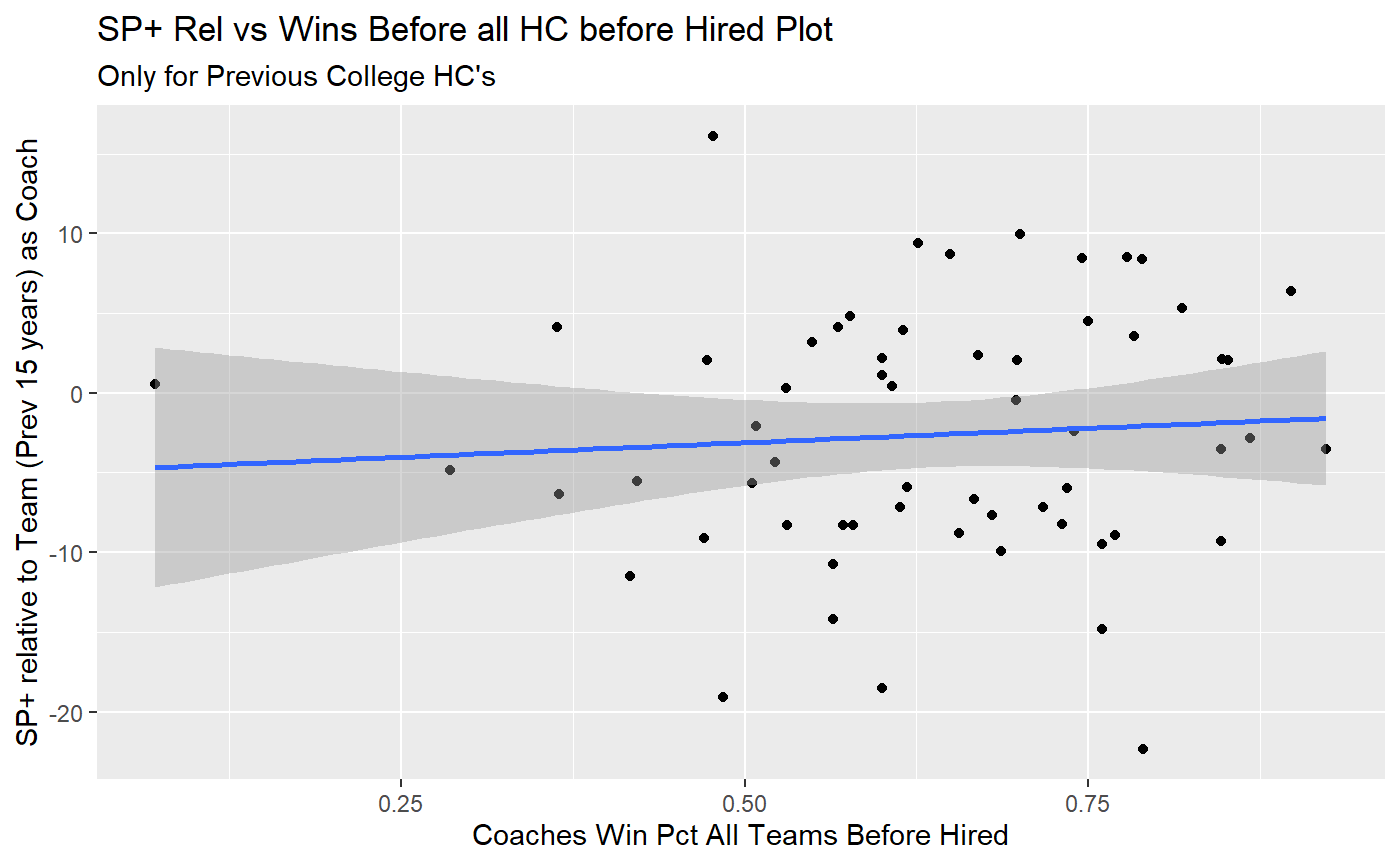</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>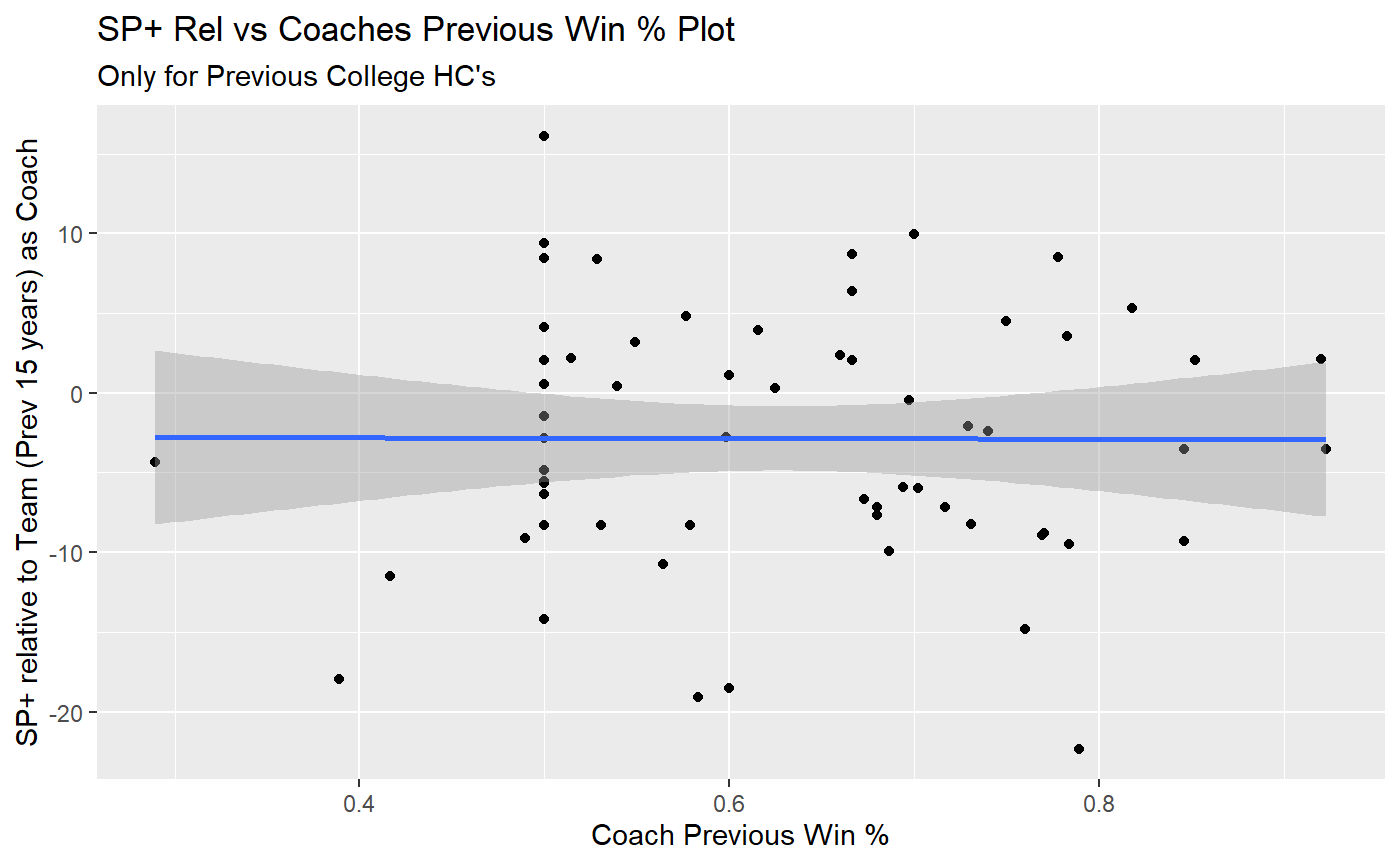</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>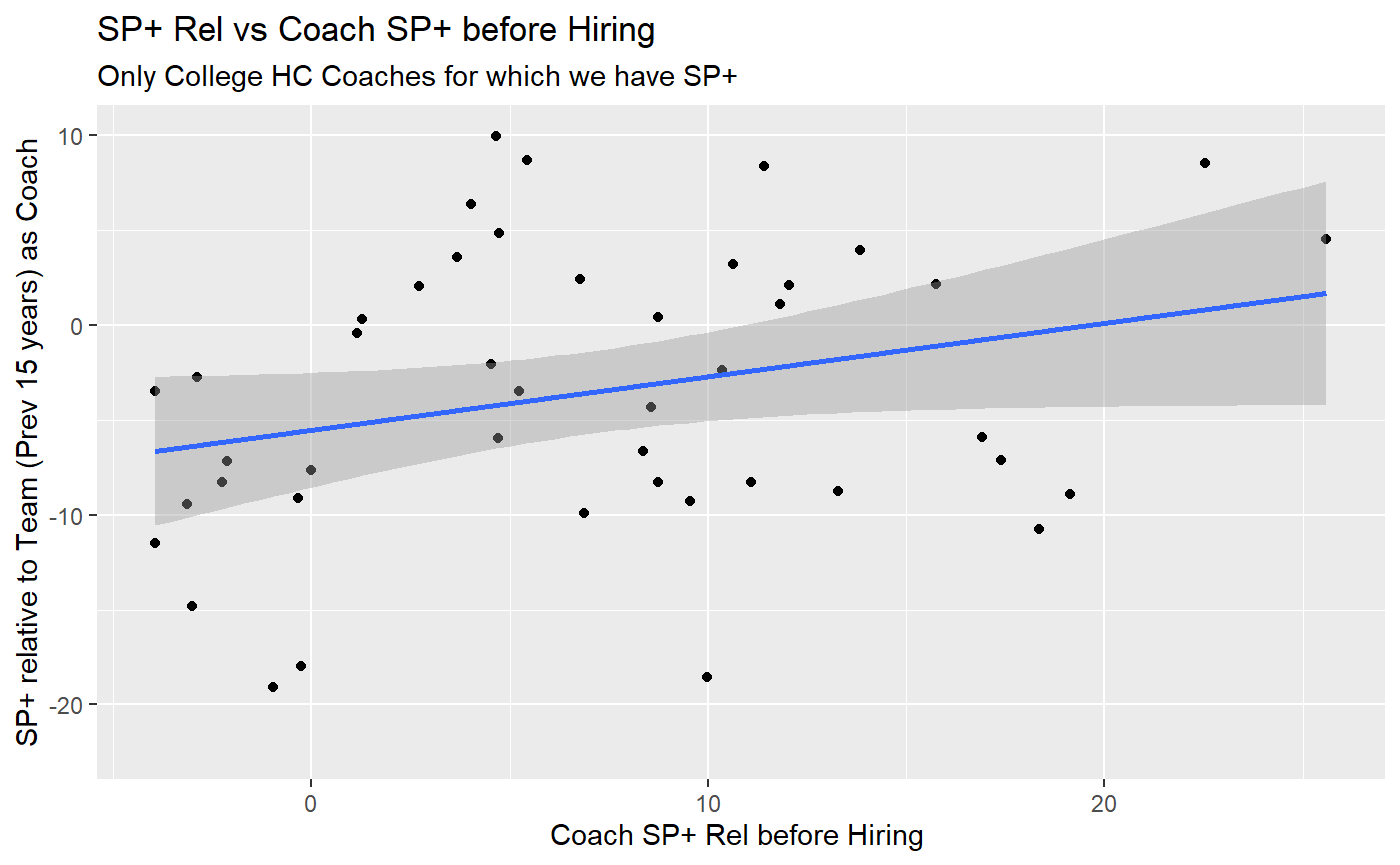</p>
</div></td>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>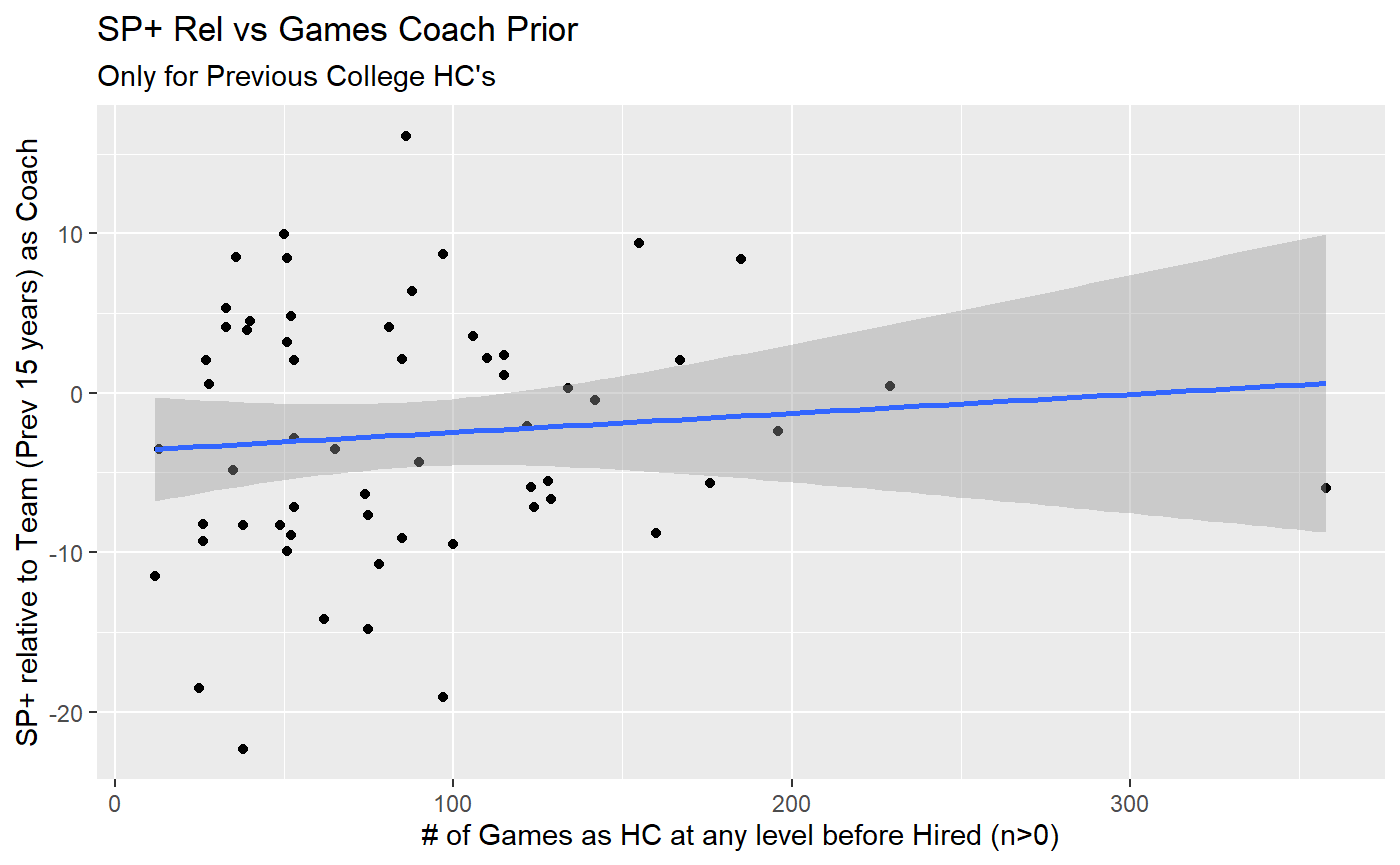</p>
</div></td>
</tr>
</tbody>
</table>

<table style="width:50%;">
<colgroup>
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%" data-layout-align="left">
<p>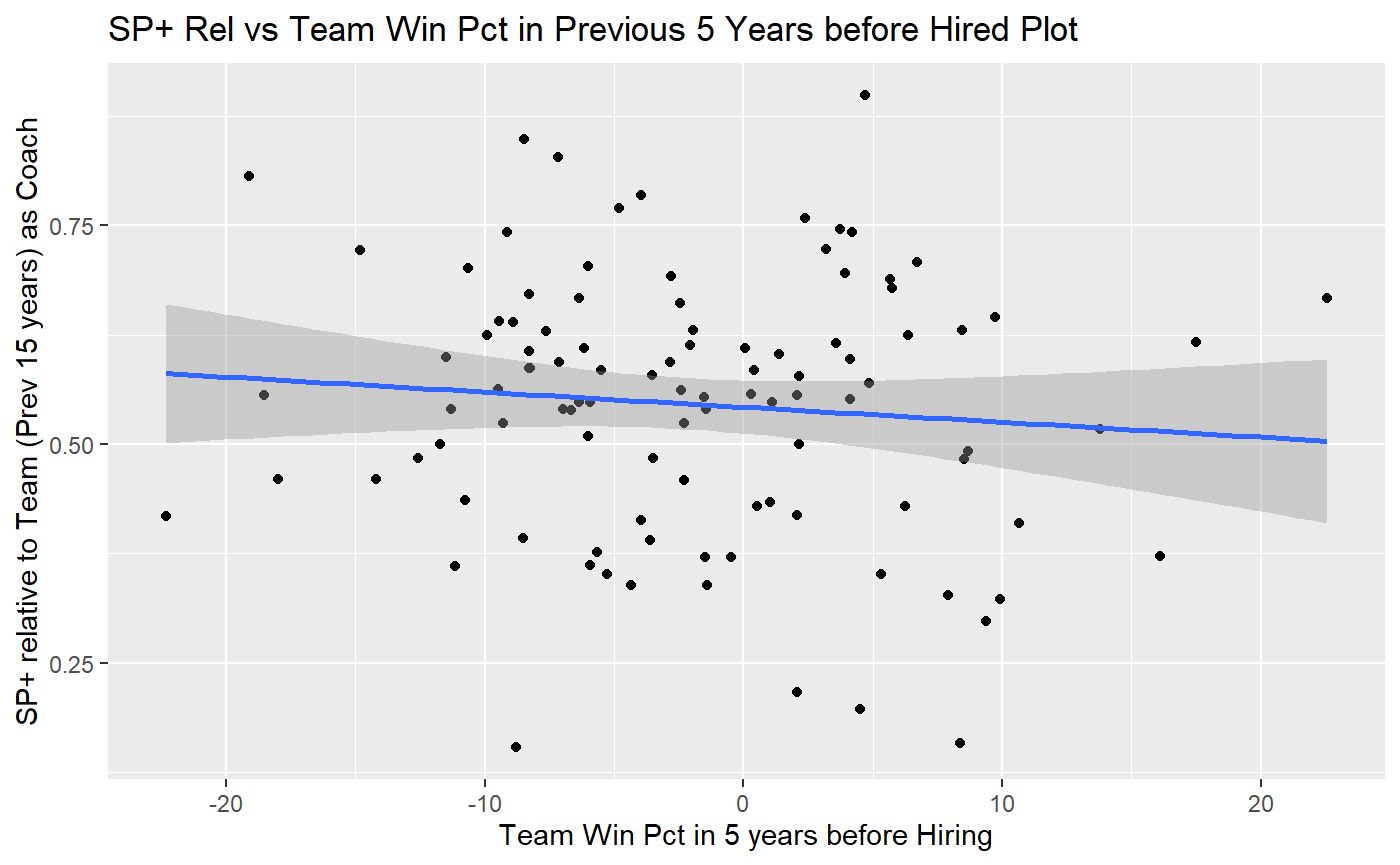</p>
</div></td>
</tr>
</tbody>
</table>

Additional plots comparing numeric predictors and *SP+ Rel*

|  | Actual: *SP+ Rel* \< 0 | Actual: *SP+ Rel* \> 0 |
|:---|---:|---:|
| **$\widehat{SP+ Rel}$ \< 0** | 57 | 25 |
| **$\widehat{Predicted SP+ Rel}$ \> 0** | 13 | 22 |